# Projet machine learning : 
## Prédiction de maladies cardiaques

### Le projet

Le projet consiste à créer un modèle permettant de prédire si un patient est atteint de maladies cardiaques à partir de plusieurs facteurs comme la pression artérielle, l'IMC, la consommation d'alcool, les antécédents familiaux, ...

### Analyse des données

Notre fichier contient 10 000 lignes correspondant à 10 000 patients. 
Pour chaque patient, nous avons 21 colonnes : 20 colonnes explicatives correspondant aux différents facteurs qui seront pris en compte dans notre prédiction, et la 21e qui nous indique si le patient est atteint d'une maladie cardiaque ou non.

Parmi les 10 000 patients, 2 000 sont atteints d'une maladie cardiaque et 8 000 ne le sont pas. Nos données sont donc déséquilibrées.

### Importation des données

In [1]:
import pandas as pd

# Charger le fichier CSV
data_brut = pd.read_csv("heart_disease.csv")

# 1. Dimensions du jeu de données
print("Dimensions :", data_brut.shape)

# 2. Aperçu des premières lignes
display(data_brut.head())

# 3. Types des colonnes
print("\nTypes des colonnes :")
print(data_brut.dtypes)

# 4. Nombre de valeurs manquantes par colonne
print("\nValeurs manquantes :")
print(data_brut.isna().sum().sort_values(ascending=False))

# 5. Répartition de la variable cible
print("\nRépartition de Heart Disease Status :")
print(data_brut["Heart Disease Status"].value_counts())

print("\nRépartition en pourcentage :")
print(
    data_brut["Heart Disease Status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Dimensions : (10000, 21)


,Age,Gender,Blood Pressure,Cholesterol Level,Exercise Habits,Smoking,Family Heart Disease,Diabetes,BMI,High Blood Pressure,...,High LDL Cholesterol,Alcohol Consumption,Stress Level,Sleep Hours,Sugar Consumption,Triglyceride Level,Fasting Blood Sugar,CRP Level,Homocysteine Level,Heart Disease Status
0,56.0,Male,153.0,155.0,High,Yes,Yes,No,24.991591,Yes,...,No,High,Medium,7.633228,Medium,342.0,NaN,12.969246,12.387250,No
1,69.0,Female,146.0,286.0,High,No,Yes,Yes,25.221799,No,...,No,Medium,High,8.744034,Medium,133.0,157.0,9.355389,19.298875,No
2,46.0,Male,126.0,216.0,Low,No,No,No,29.855447,No,...,Yes,Low,Low,4.440440,Low,393.0,92.0,12.709873,11.230926,No
3,32.0,Female,122.0,293.0,High,Yes,Yes,No,24.130477,Yes,...,Yes,Low,High,5.249405,High,293.0,94.0,12.509046,5.961958,No
4,60.0,Male,166.0,242.0,Low,Yes,Yes,Yes,20.486289,Yes,...,No,Low,High,7.030971,High,263.0,154.0,10.381259,8.153887,No



Types des colonnes :
Age                     float64
Gender                      str
Blood Pressure          float64
Cholesterol Level       float64
Exercise Habits             str
Smoking                     str
Family Heart Disease        str
Diabetes                    str
BMI                     float64
High Blood Pressure         str
Low HDL Cholesterol         str
High LDL Cholesterol        str
Alcohol Consumption         str
Stress Level                str
Sleep Hours             float64
Sugar Consumption           str
Triglyceride Level      float64
Fasting Blood Sugar     float64
CRP Level               float64
Homocysteine Level      float64
Heart Disease Status        str
dtype: object

Valeurs manquantes :
Alcohol Consumption     2586
Diabetes                  30
Sugar Consumption         30
Cholesterol Level         30
Age                       29
Triglyceride Level        26
CRP Level                 26
High LDL Cholesterol      26
High Blood Pressure       26
Low HDL C

### Traitement des données

#### Valeurs manquantes

In [2]:
# Nombre de valeurs manquantes par colonne
nb_nan = data_brut.isna().sum()

# Tableau récapitulatif
bilan_nan = pd.DataFrame({
    "Valeurs manquantes": nb_nan,
    "Pourcentage (%)": (nb_nan / len(data_brut) * 100).round(2)
})

# Trier de la colonne la plus touchée à la moins touchée
bilan_nan = bilan_nan.sort_values(
    by="Valeurs manquantes",
    ascending=False
)

display(bilan_nan)

# Nombre de lignes avec au moins une valeur manquante
nb_lignes_nan = data_brut.isna().any(axis=1).sum()

print("Nombre total de lignes :", len(data_brut))
print("Lignes avec au moins un NaN :", nb_lignes_nan)
print(
    "Pourcentage de lignes concernées :",
    round(nb_lignes_nan / len(data_brut) * 100, 2),
    "%"
)

,Valeurs manquantes,Pourcentage (%)
Alcohol Consumption,2586,25.86
Diabetes,30,0.30
Sugar Consumption,30,0.30
Cholesterol Level,30,0.30
Age,29,0.29
Triglyceride Level,26,0.26
CRP Level,26,0.26
High LDL Cholesterol,26,0.26
High Blood Pressure,26,0.26
Low HDL Cholesterol,25,0.25


Nombre total de lignes : 10000
Lignes avec au moins un NaN : 2933
Pourcentage de lignes concernées : 29.33 %


In [3]:
# Toutes les colonnes sauf Alcohol Consumption
colonnes_a_verifier = [
    colonne for colonne in data_brut.columns
    if colonne != "Alcohol Consumption"
]

# Repérer les lignes ayant au moins un NaN dans ces colonnes
lignes_a_supprimer = data_brut[colonnes_a_verifier].isna().any(axis=1)

print("Nombre de patients au départ :", len(data_brut))
print("Patients qui seraient supprimés :", lignes_a_supprimer.sum())
print("Patients conservés :", (~lignes_a_supprimer).sum())
print(
    "Pourcentage de patients supprimés :",
    round(lignes_a_supprimer.mean() * 100, 2),
    "%"
)

Nombre de patients au départ : 10000
Patients qui seraient supprimés : 468
Patients conservés : 9532
Pourcentage de patients supprimés : 4.68 %


En supprimant les lignes contenant au moins un NaN dans les colonnes autre que "Alcohol Consumption", on supprime 468 patients. 
On conserverait donc plus de 95% des données donc on choisit de supprimer ces lignes dans un premier temps.

In [4]:
print("Répartition de Alcohol Consumption :")

print(
    data_brut["Alcohol Consumption"]
    .value_counts(dropna=False)
)

print("\nRépartition en pourcentage :")

print(
    data_brut["Alcohol Consumption"]
    .value_counts(dropna=False, normalize=True)
    .mul(100)
    .round(2)
)

Répartition de Alcohol Consumption :
Alcohol Consumption
NaN       2586
Medium    2500
Low       2488
High      2426
Name: count, dtype: int64

Répartition en pourcentage :
Alcohol Consumption
NaN       25.86
Medium    25.00
Low       24.88
High      24.26
Name: proportion, dtype: float64


La répartition des différentes consommations d'alcool est très équivalente. 
Plusieurs choix sont possibles : 
- supprimer la colonne "Alcohol Consumption" car trop de données sont manquantes (25%) -> Cependant, ce choix est difficile à justifier car la consommation d'alcool et un facteur connu pour augmenter le risque de maladies cardiaques
- conserver la colonne "Alcohol Consumption" mais remplacer les NaN par "Unknown" qui indique que la consommation d'alcool du patient est inconnue -> cela introduit un biais mais permet de conserver une information importante concernant les 75% de patients qui n'ont pas de NaN

In [5]:
# Toutes les colonnes sauf Alcohol Consumption
colonnes_a_verifier = [
    colonne for colonne in data_brut.columns
    if colonne != "Alcohol Consumption"
]

# Suppression des lignes incomplètes dans ces colonnes
data = data_brut.dropna(
    subset=colonnes_a_verifier
).copy()

# Remplacement des valeurs manquantes d'alcool
data["Alcohol Consumption"] = (
    data["Alcohol Consumption"].fillna("Unknown")
)

# Vérifications
print("Dimensions après nettoyage :", data.shape)

print("\nNombre total de valeurs manquantes :")
print(data.isna().sum().sum())

print("\nRépartition de la consommation d'alcool :")
print(data["Alcohol Consumption"].value_counts())


Dimensions après nettoyage : (9532, 21)

Nombre total de valeurs manquantes :
0

Répartition de la consommation d'alcool :
Alcohol Consumption
Unknown    2465
Medium     2391
Low        2371
High       2305
Name: count, dtype: int64


Nous avons donc nettoyé nos données et nous pouvons maintenant passer à la prédiction

### Analyse de notre jeu de données

L'objectif est de mieux comprendre nos données afin de repérer de potentiels tendances / valeurs aberrantes / ... pouvant potentiellement poser problème plus tard.

In [6]:
# Nombre de patients dans chaque classe
print(data["Heart Disease Status"].value_counts())

# Proportions en pourcentage
print("\nRépartition en pourcentage :")
print(
    (data["Heart Disease Status"].value_counts(normalize=True) * 100)
    .round(2))

Heart Disease Status
No     7621
Yes    1911
Name: count, dtype: int64

Répartition en pourcentage :
Heart Disease Status
No     79.95
Yes    20.05
Name: proportion, dtype: float64


On observe que nos classes sont déséquilibrées avec environ 80% de patients sans maladie cardiaque. Cela signifie que la précision d'un modèle prédisant toujours "Non" sera de 80% et qu'il faudra donc également s'intéresser au rappel pour vérifier la proportion de patients malades effectivement identifiés.

#### Variables numériques

In [7]:
# Sélection des colonnes numériques
colonnes_numeriques = data.select_dtypes(
    include="number"
).columns

# Statistiques descriptives
print(data[colonnes_numeriques].describe().round(2))

           Age  Blood Pressure  Cholesterol Level      BMI  Sleep Hours  \
count  9532.00         9532.00            9532.00  9532.00      9532.00   
mean     49.33          149.79             225.29    29.06         6.99   
std      18.21           17.58              43.62     6.29         1.75   
min      18.00          120.00             150.00    18.01         4.00   
25%      34.00          134.00             187.00    23.66         5.45   
50%      49.00          150.00             225.00    29.06         7.00   
75%      65.00          165.00             263.00    34.48         8.53   
max      80.00          180.00             300.00    40.00        10.00   

       Triglyceride Level  Fasting Blood Sugar  CRP Level  Homocysteine Level  
count             9532.00               9532.0    9532.00             9532.00  
mean               250.39                120.1       7.46               12.45  
std                 87.13                 23.6       4.34                4.32  
min 

Pour la plupart de nos variables, on observe qu'elles sont assez dispersées avec des profils très différents. 

On peut cependant remarquer que pour l'IMC (BMI), la moyenne est à 29, ce qui est proche du seuil d'obésité, ce qui augmente le risque de maladie cardiaque.

In [8]:
# Comparaison des variables numériques selon la maladie cardiaque
resume_par_classe = data.groupby(
    "Heart Disease Status"
)[colonnes_numeriques].mean().T

print(resume_par_classe.round(2))

Heart Disease Status      No     Yes
Age                    49.38   49.12
Blood Pressure        149.92  149.28
Cholesterol Level     225.30  225.25
BMI                    28.99   29.32
Sleep Hours             6.99    6.99
Triglyceride Level    250.29  250.79
Fasting Blood Sugar   120.16  119.86
CRP Level               7.48    7.41
Homocysteine Level     12.43   12.52


On observe que les moyennes des variables numériques sont très proches entre les patients atteints et non atteints d'une maladie cardiaque. Par exemple, l'âge moyen est de 49,38 ans chez les patients non malades contre 49,12 ans chez les patients malades.

Ces résultats ne permettent pas de mettre en évidence de différences marquées entre les deux groupes. Il faut toutefois rester prudent : des moyennes similaires n'excluent pas l'existence de relations non linéaires ou d'interactions entre plusieurs variables.

#### Variables catégorielles

In [9]:
# Récupérer les variables catégorielles,sauf la variable cible
colonnes_categorielles = data.select_dtypes(
    exclude="number"
).columns.drop("Heart Disease Status")

# Comparer la répartition des catégories chez les patients No et Yes
for colonne in colonnes_categorielles:
    print(f"\n--- {colonne} ---")

    repartition = pd.crosstab(
        data[colonne],
        data["Heart Disease Status"],
        normalize="columns"
    ) * 100

    print(repartition.round(1))


--- Gender ---
Heart Disease Status    No   Yes
Gender                          
Female                49.6  51.8
Male                  50.4  48.2

--- Exercise Habits ---
Heart Disease Status    No   Yes
Exercise Habits                 
High                  33.9  33.8
Low                   32.9  32.3
Medium                33.2  33.9

--- Smoking ---
Heart Disease Status    No   Yes
Smoking                         
No                    48.8  48.4
Yes                   51.2  51.6

--- Family Heart Disease ---
Heart Disease Status    No   Yes
Family Heart Disease            
No                    50.0  51.1
Yes                   50.0  48.9

--- Diabetes ---
Heart Disease Status    No   Yes
Diabetes                        
No                    50.3  50.9
Yes                   49.7  49.1

--- High Blood Pressure ---
Heart Disease Status    No   Yes
High Blood Pressure             
No                    49.9  49.9
Yes                   50.1  50.1

--- Low HDL Cholesterol ---
Heart Disea

Pour les variables catégorielles aussi, l'écart entre les moyennes est faible.
On peut cependant noter certaines différences : 
- Alcohol Consumption : La catégorie "High" représente 25,3 % des patients malades contre 23,9 % des patients non malades
- Sugar Consumption : La catégorie "High" représente 34,7 % des patients malades contre 32,9 % des patients non malades
- Stress Level : La catégorie "Low" représente 30,8 % des patients malades contre 33,9 % des patients non malades

In [10]:
# Transformer la cible en variable binaire
# No = 0, Yes = 1
y_binaire = (
    data["Heart Disease Status"] == "Yes"
).astype(int)

# Corrélations entre les variables numériques et la cible
correlations = (
    data[colonnes_numeriques]
    .corrwith(y_binaire)
    .sort_values(key=abs, ascending=False)
)

print(correlations.round(4))

BMI                    0.0211
Blood Pressure        -0.0146
Homocysteine Level     0.0087
CRP Level             -0.0064
Age                   -0.0057
Fasting Blood Sugar   -0.0052
Triglyceride Level     0.0023
Cholesterol Level     -0.0005
Sleep Hours            0.0003
dtype: float64


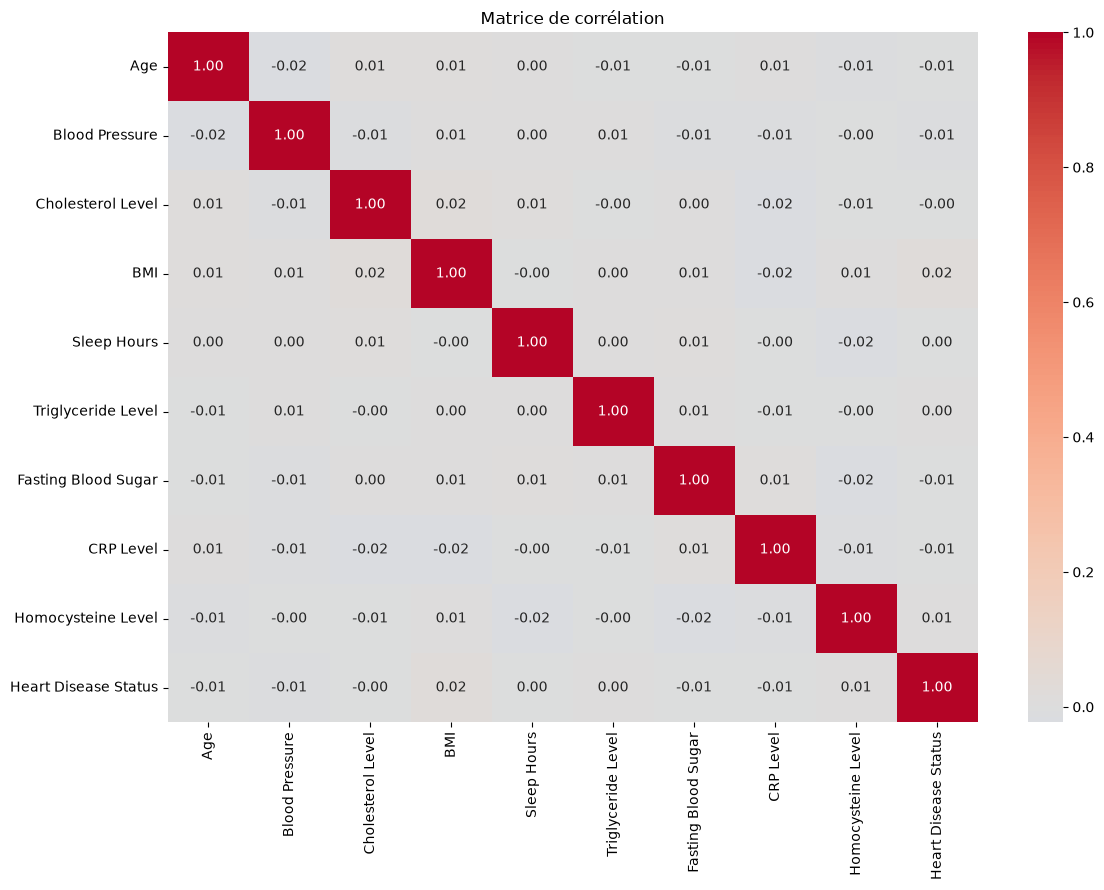

In [11]:
#Matrice de corrélation
import matplotlib.pyplot as plt
import seaborn as sns

data_corr = data.copy()
data_corr["Heart Disease Status"] = data_corr["Heart Disease Status"].map(
    {"No": 0, "Yes": 1}
)

#Sélection des variables numériques
data_numerique = data_corr.select_dtypes(include="number")

#Calcul des corrélations
matrice_corr = data_numerique.corr()

#Visualisation
plt.figure(figsize=(12, 9))
sns.heatmap(
    matrice_corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)
plt.title("Matrice de corrélation")
plt.tight_layout()
plt.show()

Les coefficients de corrélation entre les variables numériques et la variable cible sont tous très proches de zéro. Le coefficient le plus élevé en valeur absolue est celui du BMI, avec une corrélation de seulement 0,0211.

Cela indique qu'aucune relation linéaire marquée n'est mise en évidence entre les variables numériques prises individuellement et la présence d'une maladie cardiaque.

In [12]:
# Variables catégorielles à examiner
variables_a_etudier = [
    "Gender",
    "Smoking",
    "Diabetes",
    "Family Heart Disease",
    "Stress Level",
    "Sugar Consumption"
]

for colonne in variables_a_etudier:
    print(f"\n--- {colonne} ---")

    tableau = pd.crosstab(
        data[colonne],
        data["Heart Disease Status"],
        normalize="index"
    ) * 100

    print(tableau.round(2))



--- Gender ---
Heart Disease Status     No    Yes
Gender                            
Female                79.26  20.74
Male                  80.65  19.35

--- Smoking ---
Heart Disease Status     No    Yes
Smoking                           
No                    80.11  19.89
Yes                   79.80  20.20

--- Diabetes ---
Heart Disease Status     No    Yes
Diabetes                          
No                    79.77  20.23
Yes                   80.14  19.86

--- Family Heart Disease ---
Heart Disease Status     No    Yes
Family Heart Disease              
No                    79.61  20.39
Yes                   80.30  19.70

--- Stress Level ---
Heart Disease Status     No    Yes
Stress Level                      
High                  80.01  19.99
Low                   81.45  18.55
Medium                78.42  21.58

--- Sugar Consumption ---
Heart Disease Status     No    Yes
Sugar Consumption                 
High                  79.09  20.91
Low                   80.36  1

On retrouve une tendance similaire pour les variables catégorielles. Pour la plupart des variables étudiées, la proportion de patients atteints d'une maladie cardiaque reste proche de la proportion globale de 20,05 %.

Par exemple, la proportion de patients malades est de 19,89 % chez les non-fumeurs et de 20,20 % chez les fumeurs. De même, elle est de 19,70 % chez les patients ayant des antécédents familiaux et de 20,39 % chez ceux qui n'en ont pas.

Les différences observées restent donc faibles. Les variables prises individuellement semblent apporter peu d'information pour distinguer les deux classes.

### Séparation du jeu d'entraînement et de test

In [13]:
from sklearn.model_selection import train_test_split

# Variable à prédire
y = data["Heart Disease Status"].map({
    "No": 0,
    "Yes": 1
})

# Variables utilisées pour la prédiction
X = data.drop(columns=["Heart Disease Status"])

# Séparation entraînement / test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Vérifications
print("Dimensions de X_train :", X_train.shape)
print("Dimensions de X_test  :", X_test.shape)

print("\nProportion de malades dans l'entraînement :")
print((y_train.mean() * 100).round(2), "%")

print("\nProportion de malades dans le test :")
print((y_test.mean() * 100).round(2), "%")


Dimensions de X_train : (7625, 20)
Dimensions de X_test  : (1907, 20)

Proportion de malades dans l'entraînement :
20.05 %

Proportion de malades dans le test :
20.03 %


### Encodage et standardisation des données

In [14]:
# Identifier les colonnes numériques
colonnes_numeriques = X_train.select_dtypes(
    include="number"
).columns.tolist()

# Identifier les colonnes catégorielles
colonnes_categorielles = X_train.select_dtypes(
    exclude="number"
).columns.tolist()

print("Variables numériques :")
print(colonnes_numeriques)

print("\nVariables catégorielles :")
print(colonnes_categorielles)

print("\nNombre de variables numériques :", len(colonnes_numeriques))
print("Nombre de variables catégorielles :", len(colonnes_categorielles))


Variables numériques :
['Age', 'Blood Pressure', 'Cholesterol Level', 'BMI', 'Sleep Hours', 'Triglyceride Level', 'Fasting Blood Sugar', 'CRP Level', 'Homocysteine Level']

Variables catégorielles :
['Gender', 'Exercise Habits', 'Smoking', 'Family Heart Disease', 'Diabetes', 'High Blood Pressure', 'Low HDL Cholesterol', 'High LDL Cholesterol', 'Alcohol Consumption', 'Stress Level', 'Sugar Consumption']

Nombre de variables numériques : 9
Nombre de variables catégorielles : 11


In [15]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Prétraitement des variables numériques et catégorielles
process = ColumnTransformer(
    transformers=[
        ("numerique", StandardScaler(), colonnes_numeriques),
        ("categorielle", OneHotEncoder(handle_unknown="ignore"), colonnes_categorielles)
    ]
)

# Apprentissage des transformations sur les données d'entraînement
X_train_transforme = process.fit_transform(X_train)

# Application des transformations aux données de test
X_test_transforme = process.transform(X_test)

# Vérification des dimensions
print("Dimensions après prétraitement :")
print("X_train :", X_train_transforme.shape)
print("X_test  :", X_test_transforme.shape)


Dimensions après prétraitement :
X_train : (7625, 36)
X_test  : (1907, 36)


## Modélisation

### Importations

In [16]:
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)
import matplotlib.pyplot as plt


### Régression logistique

Entraînement terminé
Accuracy : 0.7996853696906135
Précision : 0.0
Recall : 0.0
F1-score : 0.0

Matrice de confusion :
[[1525    0]
 [ 382    0]]

Rapport de classification :
              precision    recall  f1-score   support

           0       0.80      1.00      0.89      1525
           1       0.00      0.00      0.00       382

    accuracy                           0.80      1907
   macro avg       0.40      0.50      0.44      1907
weighted avg       0.64      0.80      0.71      1907



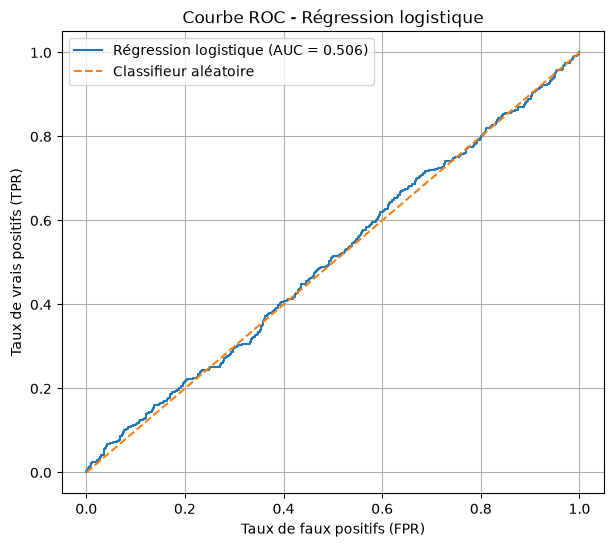

ROC-AUC : 0.5059565702514806


In [17]:
from sklearn.linear_model import LogisticRegression

# Création du modèle
modele_logistique = LogisticRegression(
    max_iter=1000, # Maximum 1000 itérations pour que le modèle trouve les meilleurs coefficients
    random_state=42
)

# Entraînement
modele_logistique.fit(X_train_transforme, y_train)

print("Entraînement terminé")

# Prédictions des classes (0 ou 1)
y_pred = modele_logistique.predict(X_test_transforme)

# Probabilités d'avoir une maladie cardiaque
y_proba = modele_logistique.predict_proba(X_test_transforme)[:, 1]


print("Accuracy :", accuracy_score(y_test, y_pred))
print("Précision :", precision_score(y_test, y_pred, zero_division=0))
print("Recall :", recall_score(y_test, y_pred, zero_division=0))
print("F1-score :", f1_score(y_test, y_pred, zero_division=0))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test, y_pred))

print("\nRapport de classification :")
print(classification_report(y_test, y_pred, zero_division=0))

# Calcul de la courbe ROC
fpr, tpr, seuils = roc_curve(y_test, y_proba)

# Calcul de l'AUC
auc = roc_auc_score(y_test, y_proba)

# Tracé
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"Régression logistique (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "--", label="Classifieur aléatoire")

plt.xlabel("Taux de faux positifs (FPR)")
plt.ylabel("Taux de vrais positifs (TPR)")
plt.title("Courbe ROC - Régression logistique")
plt.legend()
plt.grid()
plt.show()

print("ROC-AUC :", auc)

La régression logistique prédit uniquement la classe « No ». Elle identifie donc correctement les patients non malades, mais ne détecte aucun patient atteint d'une maladie cardiaque.

L'accuracy de 79,97 % peut sembler satisfaisante, mais elle est égale à la proportion de patients non malades dans le jeu de test. Le modèle prédit systématiquement « No ».

Le recall et le F1-score de la classe « Yes » sont tous deux nuls. Enfin, la ROC-AUC de 0,506 est très proche de 0,5, ce qui indique que le modèle distingue très peu les deux classes à partir des probabilités prédites.

La régression logistique ne permet donc pas d'obtenir une prédiction exploitable sur ce jeu de données.

### SVM linéaire

c:\Users\gilbe\Documents\AgroParisTech\3A\VG\MachineLearning\Projet\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


RÉSULTATS DU SVM LINÉAIRE
-------------------------
Accuracy : 0.7996853696906135
Précision : 0.0
Recall : 0.0
F1-score : 0.0
ROC-AUC : 0.4979383743884645

Matrice de confusion :
[[1525    0]
 [ 382    0]]

Rapport de classification :
              precision    recall  f1-score   support

           0       0.80      1.00      0.89      1525
           1       0.00      0.00      0.00       382

    accuracy                           0.80      1907
   macro avg       0.40      0.50      0.44      1907
weighted avg       0.64      0.80      0.71      1907



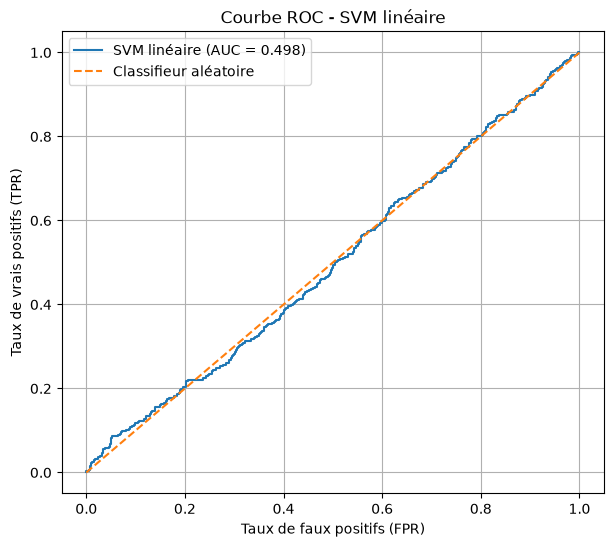

In [18]:
from sklearn.svm import SVC

modele_svm_lineaire = SVC(
    kernel="linear",
    probability=True,
    random_state=42
)

modele_svm_lineaire.fit(X_train_transforme, y_train)

# Prédiction
y_pred_svm = modele_svm_lineaire.predict(X_test_transforme)

# Probabilités de la classe 1 (maladie)
y_proba_svm = modele_svm_lineaire.predict_proba(X_test_transforme)[:, 1]

# Evaluation des prédictions
print("RÉSULTATS DU SVM LINÉAIRE")
print("-------------------------")

print("Accuracy :", accuracy_score(y_test, y_pred_svm))
print("Précision :", precision_score(y_test, y_pred_svm, zero_division=0))
print("Recall :", recall_score(y_test, y_pred_svm, zero_division=0))
print("F1-score :", f1_score(y_test, y_pred_svm, zero_division=0))
print("ROC-AUC :", roc_auc_score(y_test, y_proba_svm))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test, y_pred_svm))

print("\nRapport de classification :")
print(classification_report(y_test, y_pred_svm, zero_division=0))


# Courbe ROC
fpr_svm, tpr_svm, seuils_svm = roc_curve(y_test, y_proba_svm)
auc_svm = roc_auc_score(y_test, y_proba_svm)

plt.figure(figsize=(7, 6))
plt.plot(fpr_svm, tpr_svm, label=f"SVM linéaire (AUC = {auc_svm:.3f})")
plt.plot([0, 1], [0, 1], "--", label="Classifieur aléatoire")

plt.xlabel("Taux de faux positifs (FPR)")
plt.ylabel("Taux de vrais positifs (TPR)")
plt.title("Courbe ROC - SVM linéaire")
plt.legend()
plt.grid()
plt.show()

Le SVM linéaire aboutit à des résultats quasiment identiques à ceux de la régression logistique : il prédit également tous les patients comme non malades.

Son recall, sa précision et son F1-score pour la classe « Yes » sont nuls. Sa ROC-AUC de 0,498 est même légèrement inférieure à celle d'un classifieur aléatoire (0,5).

Ces résultats confirment que la séparation des deux classes par une frontière linéaire ne semble pas adaptée à ce jeu de données. Cela est cohérent avec l'analyse exploratoire, qui n'avait pas mis en évidence de relation linéaire marquée entre les variables numériques et la cible.

### SVM avec noyau RBF

c:\Users\gilbe\Documents\AgroParisTech\3A\VG\MachineLearning\Projet\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


RÉSULTATS DU SVM RBF
Accuracy : 0.7996853696906135
Précision : 0.0
Recall : 0.0
F1-score : 0.0
ROC-AUC : 0.5376156553085571

Matrice de confusion :
[[1525    0]
 [ 382    0]]

Rapport de classification :
              precision    recall  f1-score   support

           0       0.80      1.00      0.89      1525
           1       0.00      0.00      0.00       382

    accuracy                           0.80      1907
   macro avg       0.40      0.50      0.44      1907
weighted avg       0.64      0.80      0.71      1907



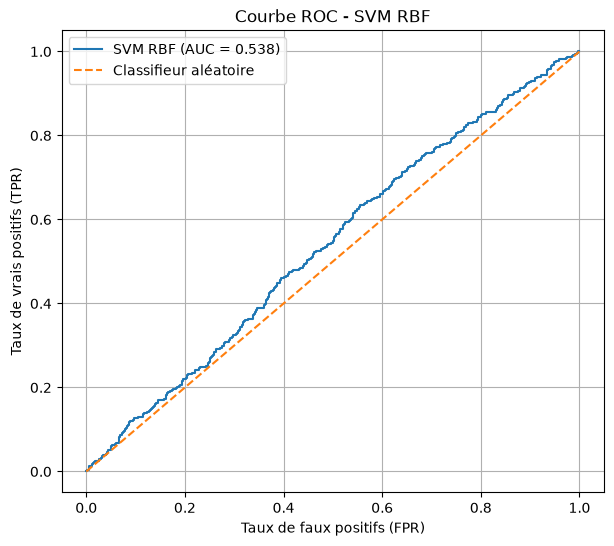

In [19]:
from sklearn.svm import SVC

#Entraînement
modele_svm_rbf = SVC(
    kernel="rbf",
    probability=True,
    random_state=42
)

modele_svm_rbf.fit(X_train_transforme, y_train)

#Prédiction
y_pred_svm_rbf = modele_svm_rbf.predict(X_test_transforme)
y_proba_svm_rbf = modele_svm_rbf.predict_proba(X_test_transforme)[:, 1]

#Évaluation
print("RÉSULTATS DU SVM RBF")
print("Accuracy :", accuracy_score(y_test, y_pred_svm_rbf))
print("Précision :", precision_score(y_test, y_pred_svm_rbf, zero_division=0))
print("Recall :", recall_score(y_test, y_pred_svm_rbf, zero_division=0))
print("F1-score :", f1_score(y_test, y_pred_svm_rbf, zero_division=0))
print("ROC-AUC :", roc_auc_score(y_test, y_proba_svm_rbf))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test, y_pred_svm_rbf))

print("\nRapport de classification :")
print(classification_report(y_test, y_pred_svm_rbf, zero_division=0))

#Courbe ROC
fpr_svm_rbf, tpr_svm_rbf, seuils_svm_rbf = roc_curve(y_test, y_proba_svm_rbf)
auc_svm_rbf = roc_auc_score(y_test, y_proba_svm_rbf)

plt.figure(figsize=(7, 6))
plt.plot(fpr_svm_rbf, tpr_svm_rbf, label=f"SVM RBF (AUC = {auc_svm_rbf:.3f})")
plt.plot([0, 1], [0, 1], "--", label="Classifieur aléatoire")
plt.xlabel("Taux de faux positifs (FPR)")
plt.ylabel("Taux de vrais positifs (TPR)")
plt.title("Courbe ROC - SVM RBF")
plt.legend()
plt.grid()
plt.show()

Le noyau RBF permet au SVM de construire une frontière de décision non linéaire. On pouvait donc espérer obtenir de meilleurs résultats qu'avec le SVM linéaire.

La ROC-AUC augmente légèrement et atteint 0,538. Le modèle semble donc apporter un peu plus d'information pour classer les patients que les deux modèles précédents.

Cependant, avec le seuil de classification par défaut, il prédit toujours tous les patients comme non malades. La précision, le recall et le F1-score de la classe « Yes » restent donc nuls.

Le passage à un modèle non linéaire ne suffit pas à résoudre le problème de discrimination entre les deux classes.

### Arbre de décision

RÉSULTATS DE L'ARBRE DE DÉCISION
Accuracy : 0.6696381751442055
Précision : 0.20192307692307693
Recall : 0.2198952879581152
F1-score : 0.21052631578947367
ROC-AUC : 0.5010951849626641

Matrice de confusion :
[[1193  332]
 [ 298   84]]

Rapport de classification :
              precision    recall  f1-score   support

           0       0.80      0.78      0.79      1525
           1       0.20      0.22      0.21       382

    accuracy                           0.67      1907
   macro avg       0.50      0.50      0.50      1907
weighted avg       0.68      0.67      0.67      1907



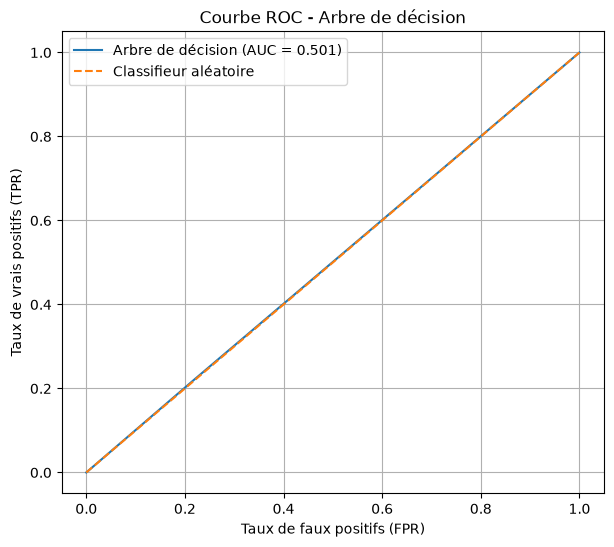

In [20]:
from sklearn.tree import DecisionTreeClassifier

#Entraînement
modele_arbre = DecisionTreeClassifier(
    random_state=42
)

modele_arbre.fit(X_train_transforme, y_train)

#Prédiction
y_pred_arbre = modele_arbre.predict(X_test_transforme)
y_proba_arbre = modele_arbre.predict_proba(X_test_transforme)[:, 1]

#Évaluation
print("RÉSULTATS DE L'ARBRE DE DÉCISION")
print("Accuracy :", accuracy_score(y_test, y_pred_arbre))
print("Précision :", precision_score(y_test, y_pred_arbre, zero_division=0))
print("Recall :", recall_score(y_test, y_pred_arbre, zero_division=0))
print("F1-score :", f1_score(y_test, y_pred_arbre, zero_division=0))
print("ROC-AUC :", roc_auc_score(y_test, y_proba_arbre))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test, y_pred_arbre))

print("\nRapport de classification :")
print(classification_report(y_test, y_pred_arbre, zero_division=0))

#Courbe ROC
fpr_arbre, tpr_arbre, seuils_arbre = roc_curve(y_test, y_proba_arbre)
auc_arbre = roc_auc_score(y_test, y_proba_arbre)

plt.figure(figsize=(7, 6))
plt.plot(fpr_arbre, tpr_arbre, label=f"Arbre de décision (AUC = {auc_arbre:.3f})")
plt.plot([0, 1], [0, 1], "--", label="Classifieur aléatoire")
plt.xlabel("Taux de faux positifs (FPR)")
plt.ylabel("Taux de vrais positifs (TPR)")
plt.title("Courbe ROC - Arbre de décision")
plt.legend()
plt.grid()
plt.show()

L'arbre de décision est le premier modèle à prédire effectivement des patients dans les deux classes.

Cependant, ses performances restent faibles. Sa précision de 20,2 % signifie que seulement environ un patient prédit comme malade sur cinq est effectivement malade. Son recall de 22,0 % indique qu'il ne détecte qu'environ un patient malade sur cinq.

Le F1-score de 0,211 traduit ce mauvais compromis entre précision et recall. De plus, la ROC-AUC de 0,501 est quasiment égale à celle d'un classifieur aléatoire.

L'arbre arrive donc à produire des prédictions dans les deux classes, mais il ne parvient pas à distinguer efficacement les patients malades des patients non malades.

### Random Forest

RÉSULTATS DE LA RANDOM FOREST
Accuracy : 0.7991609858416361
Précision : 0.0
Recall : 0.0
F1-score : 0.0
ROC-AUC : 0.5069513346493864

Matrice de confusion :
[[1524    1]
 [ 382    0]]

Rapport de classification :
              precision    recall  f1-score   support

           0       0.80      1.00      0.89      1525
           1       0.00      0.00      0.00       382

    accuracy                           0.80      1907
   macro avg       0.40      0.50      0.44      1907
weighted avg       0.64      0.80      0.71      1907



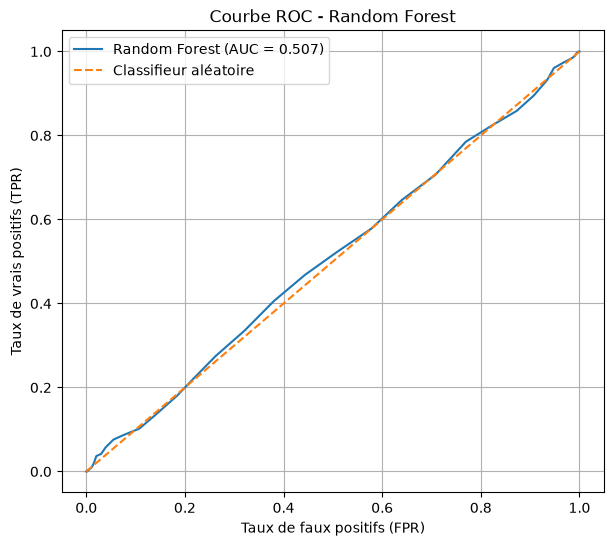

In [21]:
from sklearn.ensemble import RandomForestClassifier

#Entraînement
modele_foret = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

modele_foret.fit(X_train_transforme, y_train)

#Prédiction
y_pred_foret = modele_foret.predict(X_test_transforme)
y_proba_foret = modele_foret.predict_proba(X_test_transforme)[:, 1]

#Évaluation
print("RÉSULTATS DE LA RANDOM FOREST")
print("Accuracy :", accuracy_score(y_test, y_pred_foret))
print("Précision :", precision_score(y_test, y_pred_foret, zero_division=0))
print("Recall :", recall_score(y_test, y_pred_foret, zero_division=0))
print("F1-score :", f1_score(y_test, y_pred_foret, zero_division=0))
print("ROC-AUC :", roc_auc_score(y_test, y_proba_foret))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test, y_pred_foret))

print("\nRapport de classification :")
print(classification_report(y_test, y_pred_foret, zero_division=0))

#Courbe ROC
fpr_foret, tpr_foret, seuils_foret = roc_curve(y_test, y_proba_foret)
auc_foret = roc_auc_score(y_test, y_proba_foret)

plt.figure(figsize=(7, 6))
plt.plot(fpr_foret, tpr_foret, label=f"Random Forest (AUC = {auc_foret:.3f})")
plt.plot([0, 1], [0, 1], "--", label="Classifieur aléatoire")
plt.xlabel("Taux de faux positifs (FPR)")
plt.ylabel("Taux de vrais positifs (TPR)")
plt.title("Courbe ROC - Random Forest")
plt.legend()
plt.grid()
plt.show()

La Random Forest combine plusieurs arbres de décision afin d'améliorer la capacité de généralisation du modèle.

Pourtant, les résultats obtenus ne montrent aucune amélioration significative. Comme la régression logistique et les SVM, le modèle prédit presque exclusivement la classe « No » : un seul patient est prédit comme malade, et il s'agit d'un faux positif.

Le recall et le F1-score de la classe « Yes » sont donc nuls. La ROC-AUC de 0,507 reste également très proche de 0,5.

L'utilisation d'un ensemble d'arbres ne permet donc pas de faire émerger de discrimination entre nos classes.

### Gradient Boosting

RÉSULTATS DU GRADIENT BOOSTING
Accuracy : 0.7986366019926586
Précision : 0.25
Recall : 0.002617801047120419
F1-score : 0.0051813471502590676
ROC-AUC : 0.49839498755471634

Matrice de confusion :
[[1522    3]
 [ 381    1]]

Rapport de classification :
              precision    recall  f1-score   support

           0       0.80      1.00      0.89      1525
           1       0.25      0.00      0.01       382

    accuracy                           0.80      1907
   macro avg       0.52      0.50      0.45      1907
weighted avg       0.69      0.80      0.71      1907



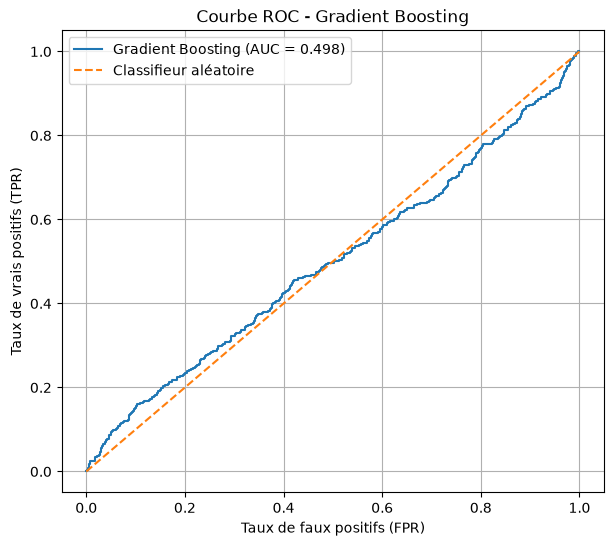

In [22]:
from sklearn.ensemble import GradientBoostingClassifier

#Entraînement
modele_gradient = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

modele_gradient.fit(X_train_transforme, y_train)

#Prédiction
y_pred_gradient = modele_gradient.predict(X_test_transforme)
y_proba_gradient = modele_gradient.predict_proba(X_test_transforme)[:, 1]

#Évaluation
print("RÉSULTATS DU GRADIENT BOOSTING")
print("Accuracy :", accuracy_score(y_test, y_pred_gradient))
print("Précision :", precision_score(y_test, y_pred_gradient, zero_division=0))
print("Recall :", recall_score(y_test, y_pred_gradient, zero_division=0))
print("F1-score :", f1_score(y_test, y_pred_gradient, zero_division=0))
print("ROC-AUC :", roc_auc_score(y_test, y_proba_gradient))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test, y_pred_gradient))

print("\nRapport de classification :")
print(classification_report(y_test, y_pred_gradient, zero_division=0))

#Courbe ROC
fpr_gradient, tpr_gradient, seuils_gradient = roc_curve(y_test, y_proba_gradient)
auc_gradient = roc_auc_score(y_test, y_proba_gradient)

plt.figure(figsize=(7, 6))
plt.plot(fpr_gradient, tpr_gradient, label=f"Gradient Boosting (AUC = {auc_gradient:.3f})")
plt.plot([0, 1], [0, 1], "--", label="Classifieur aléatoire")
plt.xlabel("Taux de faux positifs (FPR)")
plt.ylabel("Taux de vrais positifs (TPR)")
plt.title("Courbe ROC - Gradient Boosting")
plt.legend()
plt.grid()
plt.show()

Le Gradient Boosting construit successivement des arbres afin de corriger les erreurs des modèles précédents. Malgré cette approche, les performances restent très faibles.

Le modèle ne détecte qu'un seul patient malade sur les 382 présents dans le jeu de test, soit un recall de seulement 0,26 %. Sa précision est de 25 %, mais elle repose sur une seule prédiction correcte.

La ROC-AUC de 0,498 est inférieure à 0,5 et ne montre pas de capacité de discrimination satisfaisante.

Ce modèle plus complexe ne permet donc pas d'améliorer les résultats obtenus avec les modèles précédents.

### Réseau de neurones MLP

RÉSULTATS DU MLP
Accuracy : 0.7996853696906135
Précision : 0.0
Recall : 0.0
F1-score : 0.0
ROC-AUC : 0.49414642519955365

Matrice de confusion :
[[1525    0]
 [ 382    0]]

Rapport de classification :
              precision    recall  f1-score   support

           0       0.80      1.00      0.89      1525
           1       0.00      0.00      0.00       382

    accuracy                           0.80      1907
   macro avg       0.40      0.50      0.44      1907
weighted avg       0.64      0.80      0.71      1907



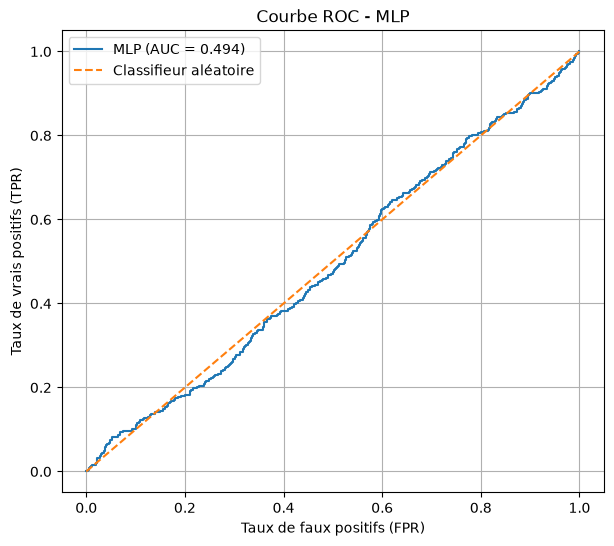

In [23]:
from sklearn.neural_network import MLPClassifier

#Entraînement
modele_mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    max_iter=500,
    early_stopping=True,
    random_state=42
)

modele_mlp.fit(X_train_transforme, y_train)

#Prédiction
y_pred_mlp = modele_mlp.predict(X_test_transforme)
y_proba_mlp = modele_mlp.predict_proba(X_test_transforme)[:, 1]

#Évaluation
print("RÉSULTATS DU MLP")
print("Accuracy :", accuracy_score(y_test, y_pred_mlp))
print("Précision :", precision_score(y_test, y_pred_mlp, zero_division=0))
print("Recall :", recall_score(y_test, y_pred_mlp, zero_division=0))
print("F1-score :", f1_score(y_test, y_pred_mlp, zero_division=0))
print("ROC-AUC :", roc_auc_score(y_test, y_proba_mlp))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test, y_pred_mlp))

print("\nRapport de classification :")
print(classification_report(y_test, y_pred_mlp, zero_division=0))

#Courbe ROC
fpr_mlp, tpr_mlp, seuils_mlp = roc_curve(y_test, y_proba_mlp)
auc_mlp = roc_auc_score(y_test, y_proba_mlp)

plt.figure(figsize=(7, 6))
plt.plot(fpr_mlp, tpr_mlp, label=f"MLP (AUC = {auc_mlp:.3f})")
plt.plot([0, 1], [0, 1], "--", label="Classifieur aléatoire")
plt.xlabel("Taux de faux positifs (FPR)")
plt.ylabel("Taux de vrais positifs (TPR)")
plt.title("Courbe ROC - MLP")
plt.legend()
plt.grid()
plt.show()

Enfin, nous testons un réseau de neurones multicouche (MLP), capable de modéliser des relations complexes et non linéaires entre les variables.

Les résultats sont cependant similaires à ceux des premiers modèles : le MLP prédit uniquement la classe « No ». Il obtient une accuracy de 79,97 %, mais un recall et un F1-score nuls pour la classe « Yes ».

Sa ROC-AUC de 0,494 est également très proche de 0,5.

Même avec un modèle plus complexe, nous ne parvenons donc pas à identifier correctement les patients atteints d'une maladie cardiaque.

## Bilan de la modélisation

Nous avons testé plusieurs familles de modèles afin de prédire la présence d'une maladie cardiaque :

- **Modèles linéaires** : régression logistique et SVM linéaire ;
- **Modèles non linéaires** : SVM avec noyau RBF et arbre de décision ;
- **Méthodes ensemblistes** : Random Forest et Gradient Boosting ;
- **Réseau de neurones** : MLP.

Malgré la diversité de ces approches, aucun modèle ne parvient à obtenir des performances satisfaisantes.

Plusieurs constats expliquent ces difficultés :

1. **Une faible association entre les variables et la cible :** l'analyse exploratoire a montré que les moyennes des variables numériques et les distributions des variables catégorielles sont très proches entre les patients malades et non malades. Les coefficients de corrélation entre les variables numériques et la cible sont également tous très proches de zéro.

2. **Une faible capacité de discrimination :** les ROC-AUC obtenues sont comprises entre 0,494 et 0,538. Elles sont donc toutes proches de 0,5, valeur correspondant à un classement aléatoire des patients. Même les modèles non linéaires et les méthodes ensemblistes ne parviennent pas à améliorer significativement cette discrimination.

3. **Une difficulté à détecter les patients malades :** plusieurs modèles prédisent uniquement la classe majoritaire « No ». Leur accuracy est alors proche de 80 %, mais leur recall pour la classe « Yes » est nul. Cette accuracy est donc trompeuse et ne traduit pas une réelle capacité de prédiction.

Ces résultats ne prouvent pas qu'aucune relation prédictive n'existe dans ce jeu de données. Ils montrent néanmoins que les variables disponibles ne permettent pas aux différentes approches testées de distinguer efficacement les patients atteints d'une maladie cardiaque.

**Nous avons donc décidé de changer de jeu de données et de nous orienter vers le dataset Framingham.** Celui-ci nous permettra de reprendre notre démarche de classification sur un autre ensemble de données, avec l'objectif d'obtenir des résultats plus pertinents et d'évaluer à nouveau la capacité des modèles à identifier les patients présentant un risque de maladie cardiovasculaire.

# Deuxième partie — Étude du jeu de données de Framingham

Après une première exploration sur un autre jeu de données, nous poursuivons le projet avec le jeu de données de Framingham. Cette seconde approche vise à prédire la survenue d'une maladie coronarienne dans les dix années à venir (`TenYearCHD`).

Les deux jeux de données ne reposent pas sur les mêmes variables ni sur la même définition de la cible. Les résultats obtenus dans cette partie seront donc étudiés séparément de ceux de la première partie.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Chargement des données
data_f = pd.read_csv("framingham.csv")

#Dimensions du dataset
print("Dimensions :", data_f.shape)

#Aperçu des données
display(data_f.head())


Dimensions : (4240, 16)


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


## 1. Découverte du jeu de données

### 1.1. Variable cible : `TenYearCHD`

La variable cible indique si un patient a développé une maladie coronarienne au cours des dix années suivant son observation :
- `0` : aucune maladie coronarienne observée dans les dix années ;
- `1` : maladie coronarienne observée dans les dix années.


TenYearCHD
0    3596
1     644
Name: count, dtype: int64
TenYearCHD
0    84.811321
1    15.188679
Name: proportion, dtype: float64


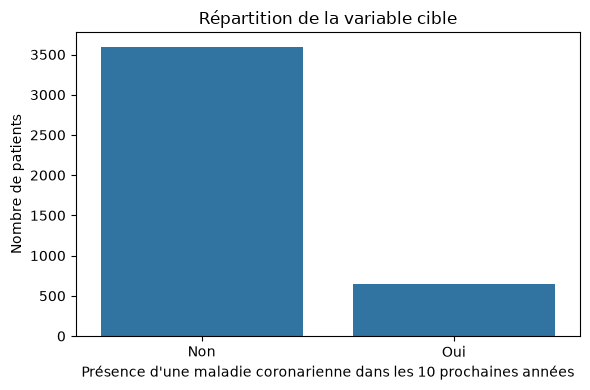

In [2]:
#Effectifs de chaque classe
print(data_f["TenYearCHD"].value_counts())

#Pourcentages de chaque classe
print(data_f["TenYearCHD"].value_counts(normalize=True) * 100)

#Visualisation
plt.figure(figsize=(6, 4))
sns.countplot(data=data_f, x="TenYearCHD")
plt.title("Répartition de la variable cible")
plt.xlabel("Présence d'une maladie coronarienne dans les 10 prochaines années")
plt.ylabel("Nombre de patients")
plt.xticks([0, 1], ["Non", "Oui"])
plt.tight_layout()
plt.show()

La variable TenYearCHD correspond à la prédiction de si le patient sera atteint d'une maladie coronarienne dans les 10 prochaines années ou non :
- 0 si pas de maladie coronarienne dans les 10 prochaines années
- 1 si maladie coronarienne dans les 10 prochaines années

On observe un déséquilibre des classes dans notre jeu de données :
- 85 % de Non
- 15 % de Oui

### 1.2. Valeurs manquantes

Nous commençons par quantifier les valeurs manquantes dans chaque variable, puis par déterminer le nombre de patients concernés par au moins une valeur manquante.


In [3]:
#Nombre de valeurs manquantes par colonne
nb_nan_f = data_f.isna().sum()

#Pourcentage de valeurs manquantes par colonne
pourcentage_nan_f = (nb_nan_f / len(data_f)) * 100

#Tableau récapitulatif
table_nan_f = pd.DataFrame({
    "Nombre de valeurs manquantes": nb_nan_f,
    "Pourcentage (%)": pourcentage_nan_f
})

display(table_nan_f)

,Nombre de valeurs manquantes,Pourcentage (%)
male,0,0.000000
age,0,0.000000
education,105,2.476415
currentSmoker,0,0.000000
cigsPerDay,29,0.683962
BPMeds,53,1.250000
prevalentStroke,0,0.000000
prevalentHyp,0,0.000000
diabetes,0,0.000000
totChol,50,1.179245


In [4]:
#Nombre de lignes contenant au moins un NaN
nb_lignes_nan_f = data_f.isna().any(axis=1).sum()

#Pourcentage de lignes concernées
pourcentage_lignes_nan_f = (nb_lignes_nan_f / len(data_f)) * 100

print("Nombre de lignes avec au moins un NaN :", nb_lignes_nan_f)
print("Pourcentage de lignes concernées :", round(pourcentage_lignes_nan_f, 2), "%")

Nombre de lignes avec au moins un NaN : 582
Pourcentage de lignes concernées : 13.73 %


### 1.3. Analyse descriptive des variables


In [5]:
#Informations sur les variables
data_f.info()

#Statistiques descriptives
display(data_f.describe())

<class 'pandas.DataFrame'>
RangeIndex: 4240 entries, 0 to 4239
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4240 non-null   int64  
 1   age              4240 non-null   int64  
 2   education        4135 non-null   float64
 3   currentSmoker    4240 non-null   int64  
 4   cigsPerDay       4211 non-null   float64
 5   BPMeds           4187 non-null   float64
 6   prevalentStroke  4240 non-null   int64  
 7   prevalentHyp     4240 non-null   int64  
 8   diabetes         4240 non-null   int64  
 9   totChol          4190 non-null   float64
 10  sysBP            4240 non-null   float64
 11  diaBP            4240 non-null   float64
 12  BMI              4221 non-null   float64
 13  heartRate        4239 non-null   float64
 14  glucose          3852 non-null   float64
 15  TenYearCHD       4240 non-null   int64  
dtypes: float64(9), int64(7)
memory usage: 530.1 KB


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
count,4240.000000,4240.000000,4135.000000,4240.000000,4211.000000,4187.000000,4240.000000,4240.000000,4240.000000,4190.000000,4240.000000,4240.000000,4221.000000,4239.000000,3852.000000,4240.000000
mean,0.429245,49.580189,1.979444,0.494104,9.005937,0.029615,0.005896,0.310613,0.025708,236.699523,132.354599,82.897759,25.800801,75.878981,81.963655,0.151887
std,0.495027,8.572942,1.019791,0.500024,11.922462,0.169544,0.076569,0.462799,0.158280,44.591284,22.033300,11.910394,4.079840,12.025348,23.954335,0.358953
min,0.000000,32.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,107.000000,83.500000,48.000000,15.540000,44.000000,40.000000,0.000000
25%,0.000000,42.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,206.000000,117.000000,75.000000,23.070000,68.000000,71.000000,0.000000
50%,0.000000,49.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,234.000000,128.000000,82.000000,25.400000,75.000000,78.000000,0.000000
75%,1.000000,56.000000,3.000000,1.000000,20.000000,0.000000,0.000000,1.000000,0.000000,263.000000,144.000000,90.000000,28.040000,83.000000,87.000000,0.000000
max,1.000000,70.000000,4.000000,1.000000,70.000000,1.000000,1.000000,1.000000,1.000000,696.000000,295.000000,142.500000,56.800000,143.000000,394.000000,1.000000


In [6]:
#Valeurs distinctes de chaque variable
for colonne in data_f.columns:
    print("\nVariable :", colonne)
    print("Nombre de valeurs distinctes :", data_f[colonne].nunique())
    print("Valeurs observées :")
    print(data_f[colonne].value_counts(dropna=False).sort_index())


Variable : male
Nombre de valeurs distinctes : 2
Valeurs observées :
male
0    2420
1    1820
Name: count, dtype: int64

Variable : age
Nombre de valeurs distinctes : 39
Valeurs observées :
age
32      1
33      5
34     18
35     42
36     84
37     92
38    144
39    170
40    192
41    174
42    180
43    159
44    166
45    162
46    182
47    141
48    173
49    132
50    140
51    146
52    149
53    139
54    132
55    145
56    123
57    123
58    117
59    119
60    111
61    110
62     99
63    110
64     93
65     57
66     38
67     45
68     18
69      7
70      2
Name: count, dtype: int64

Variable : education
Nombre de valeurs distinctes : 4
Valeurs observées :
education
1.0    1720
2.0    1253
3.0     689
4.0     473
NaN     105
Name: count, dtype: int64

Variable : currentSmoker
Nombre de valeurs distinctes : 2
Valeurs observées :
currentSmoker
0    2145
1    2095
Name: count, dtype: int64

Variable : cigsPerDay
Nombre de valeurs distinctes : 33
Valeurs observées :
ci

Le jeu de données contient **4 240 observations**, correspondant à 4 240 patients, et **15 variables explicatives**, en plus de la variable cible `TenYearCHD`.

Les variables peuvent être regroupées comme suit :

- **Variables binaires** : `male`, `currentSmoker`, `BPMeds`, `prevalentStroke`, `prevalentHyp` et `diabetes`.
- **Variables quantitatives** : `age`, `cigsPerDay`, `totChol`, `sysBP`, `diaBP`, `BMI`, `heartRate` et `glucose`.
- **Variable catégorielle ordinale** : `education`, qui représente le niveau d'éducation.

Bien que plusieurs variables soient codées numériquement, leur nature doit être prise en compte dans l'analyse et le prétraitement.


#### 1.3.1. Variables quantitatives


In [7]:
#Sélection des variables quantitatives
variables_quantitatives_f = [
    "age", "cigsPerDay", "totChol", "sysBP",
    "diaBP", "BMI", "heartRate", "glucose"
]

#Statistiques descriptives
display(data_f[variables_quantitatives_f].describe().T)

,count,mean,std,min,25%,50%,75%,max
age,4240.0,49.580189,8.572942,32.00,42.00,49.0,56.00,70.0
cigsPerDay,4211.0,9.005937,11.922462,0.00,0.00,0.0,20.00,70.0
totChol,4190.0,236.699523,44.591284,107.00,206.00,234.0,263.00,696.0
sysBP,4240.0,132.354599,22.033300,83.50,117.00,128.0,144.00,295.0
diaBP,4240.0,82.897759,11.910394,48.00,75.00,82.0,90.00,142.5
BMI,4221.0,25.800801,4.079840,15.54,23.07,25.4,28.04,56.8
heartRate,4239.0,75.878981,12.025348,44.00,68.00,75.0,83.00,143.0
glucose,3852.0,81.963655,23.954335,40.00,71.00,78.0,87.00,394.0


In [8]:
#Détection des valeurs potentiellement atypiques avec la méthode IQR
resultats_iqr_f = []

for colonne in variables_quantitatives_f:
    Q1 = data_f[colonne].quantile(0.25)
    Q3 = data_f[colonne].quantile(0.75)

    IQR = Q3 - Q1

    borne_inf = Q1 - 1.5 * IQR
    borne_sup = Q3 + 1.5 * IQR

    nb_atypiques = (
        (data_f[colonne] < borne_inf) |
        (data_f[colonne] > borne_sup)
    ).sum()

    resultats_iqr_f.append({
        "Variable": colonne,
        "Borne inférieure": borne_inf,
        "Borne supérieure": borne_sup,
        "Nombre de valeurs atypiques": nb_atypiques,
        "Pourcentage (%)": nb_atypiques / data_f[colonne].notna().sum() * 100
    })

table_iqr_f = pd.DataFrame(resultats_iqr_f)
display(table_iqr_f.round(2))

,Variable,Borne inférieure,Borne supérieure,Nombre de valeurs atypiques,Pourcentage (%)
0,age,21.00,77.00,0,0.00
1,cigsPerDay,-30.00,50.00,12,0.28
2,totChol,120.50,348.50,56,1.34
3,sysBP,76.50,184.50,126,2.97
4,diaBP,52.50,112.50,77,1.82
5,BMI,15.62,35.49,97,2.30
6,heartRate,45.50,105.50,76,1.79
7,glucose,47.00,111.00,188,4.88


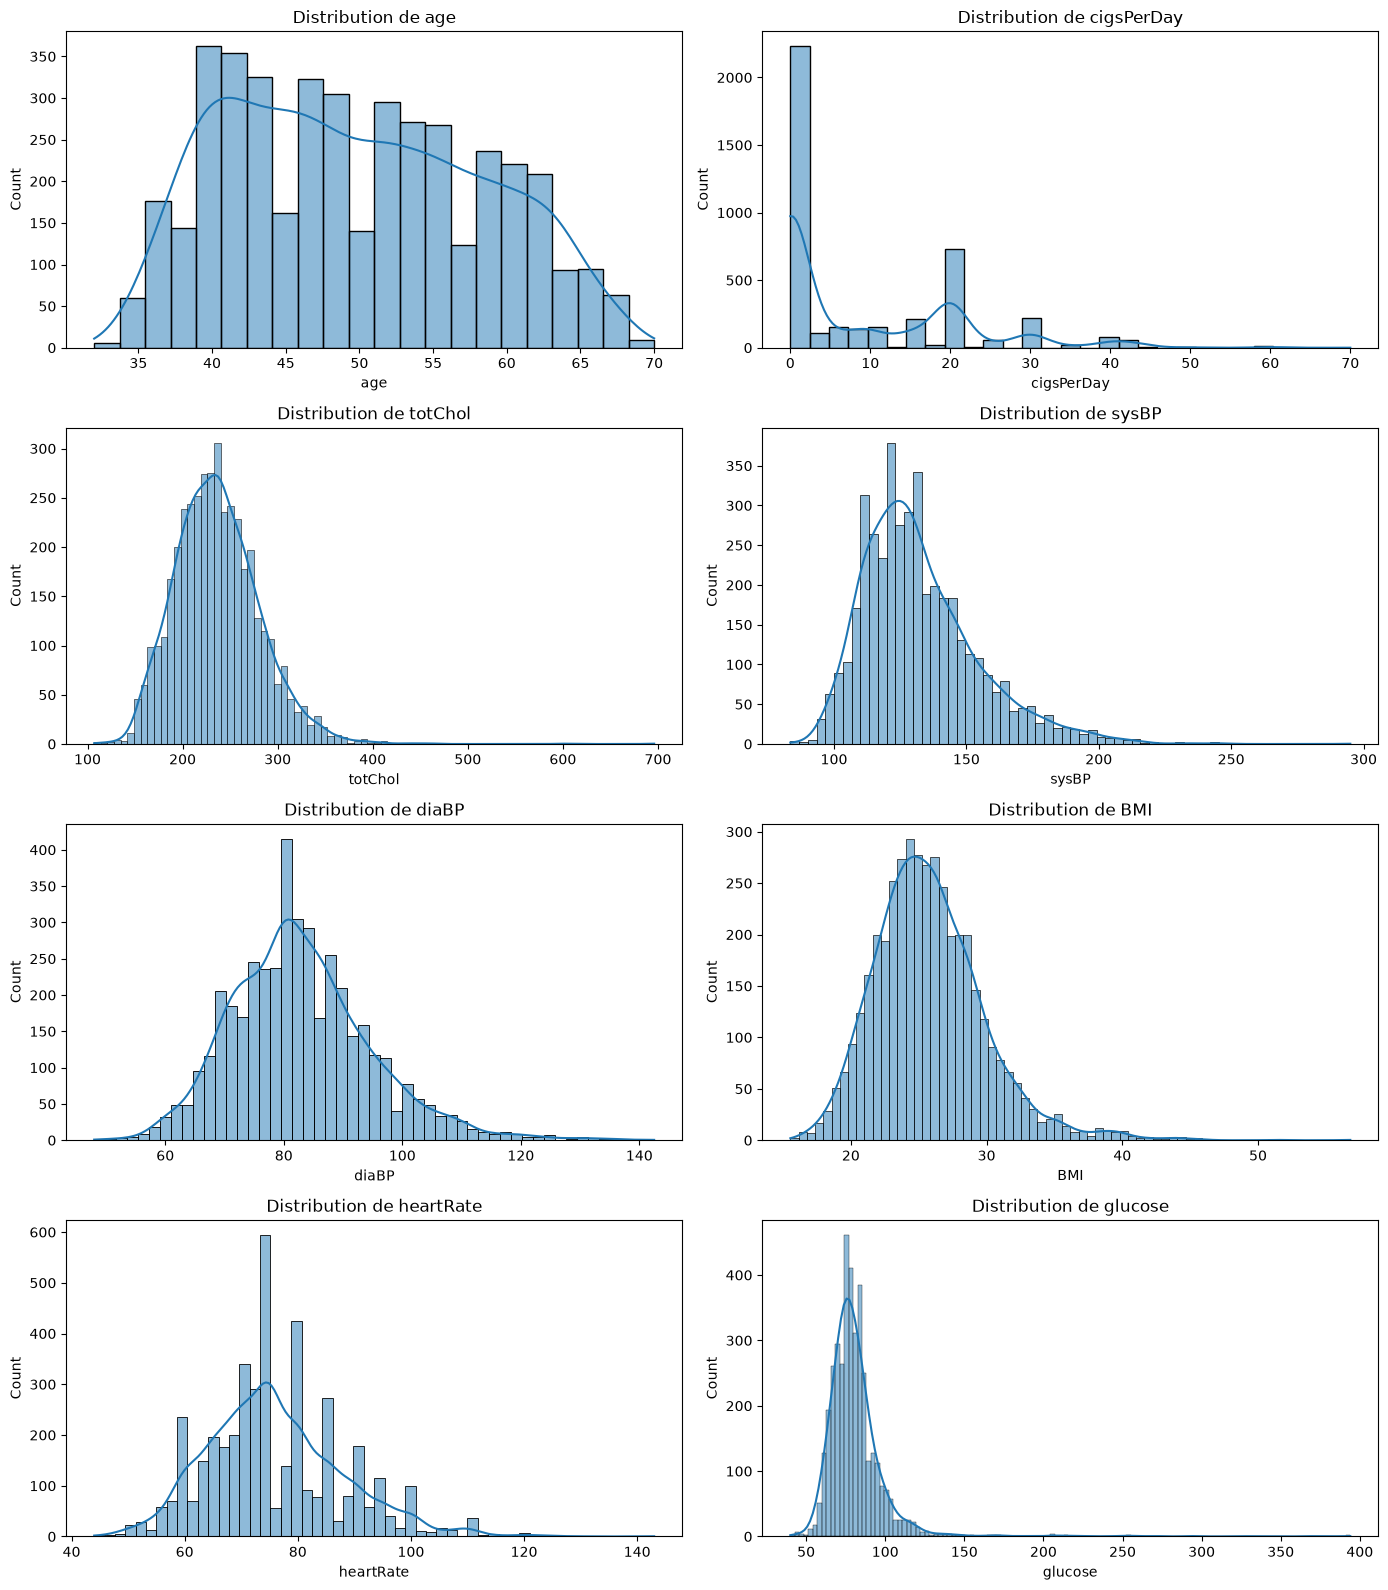

In [9]:
# Histogrammes des variables quantitatives
variables_quantitatives_f = [
    "age", "cigsPerDay", "totChol", "sysBP",
    "diaBP", "BMI", "heartRate", "glucose"
]

fig, axes = plt.subplots(4, 2, figsize=(14, 16))

for colonne, ax in zip(variables_quantitatives_f, axes.flatten()):
    sns.histplot(data=data_f, x=colonne, kde=True, ax=ax)
    ax.set_title(f"Distribution de {colonne}")

plt.tight_layout()
plt.show()

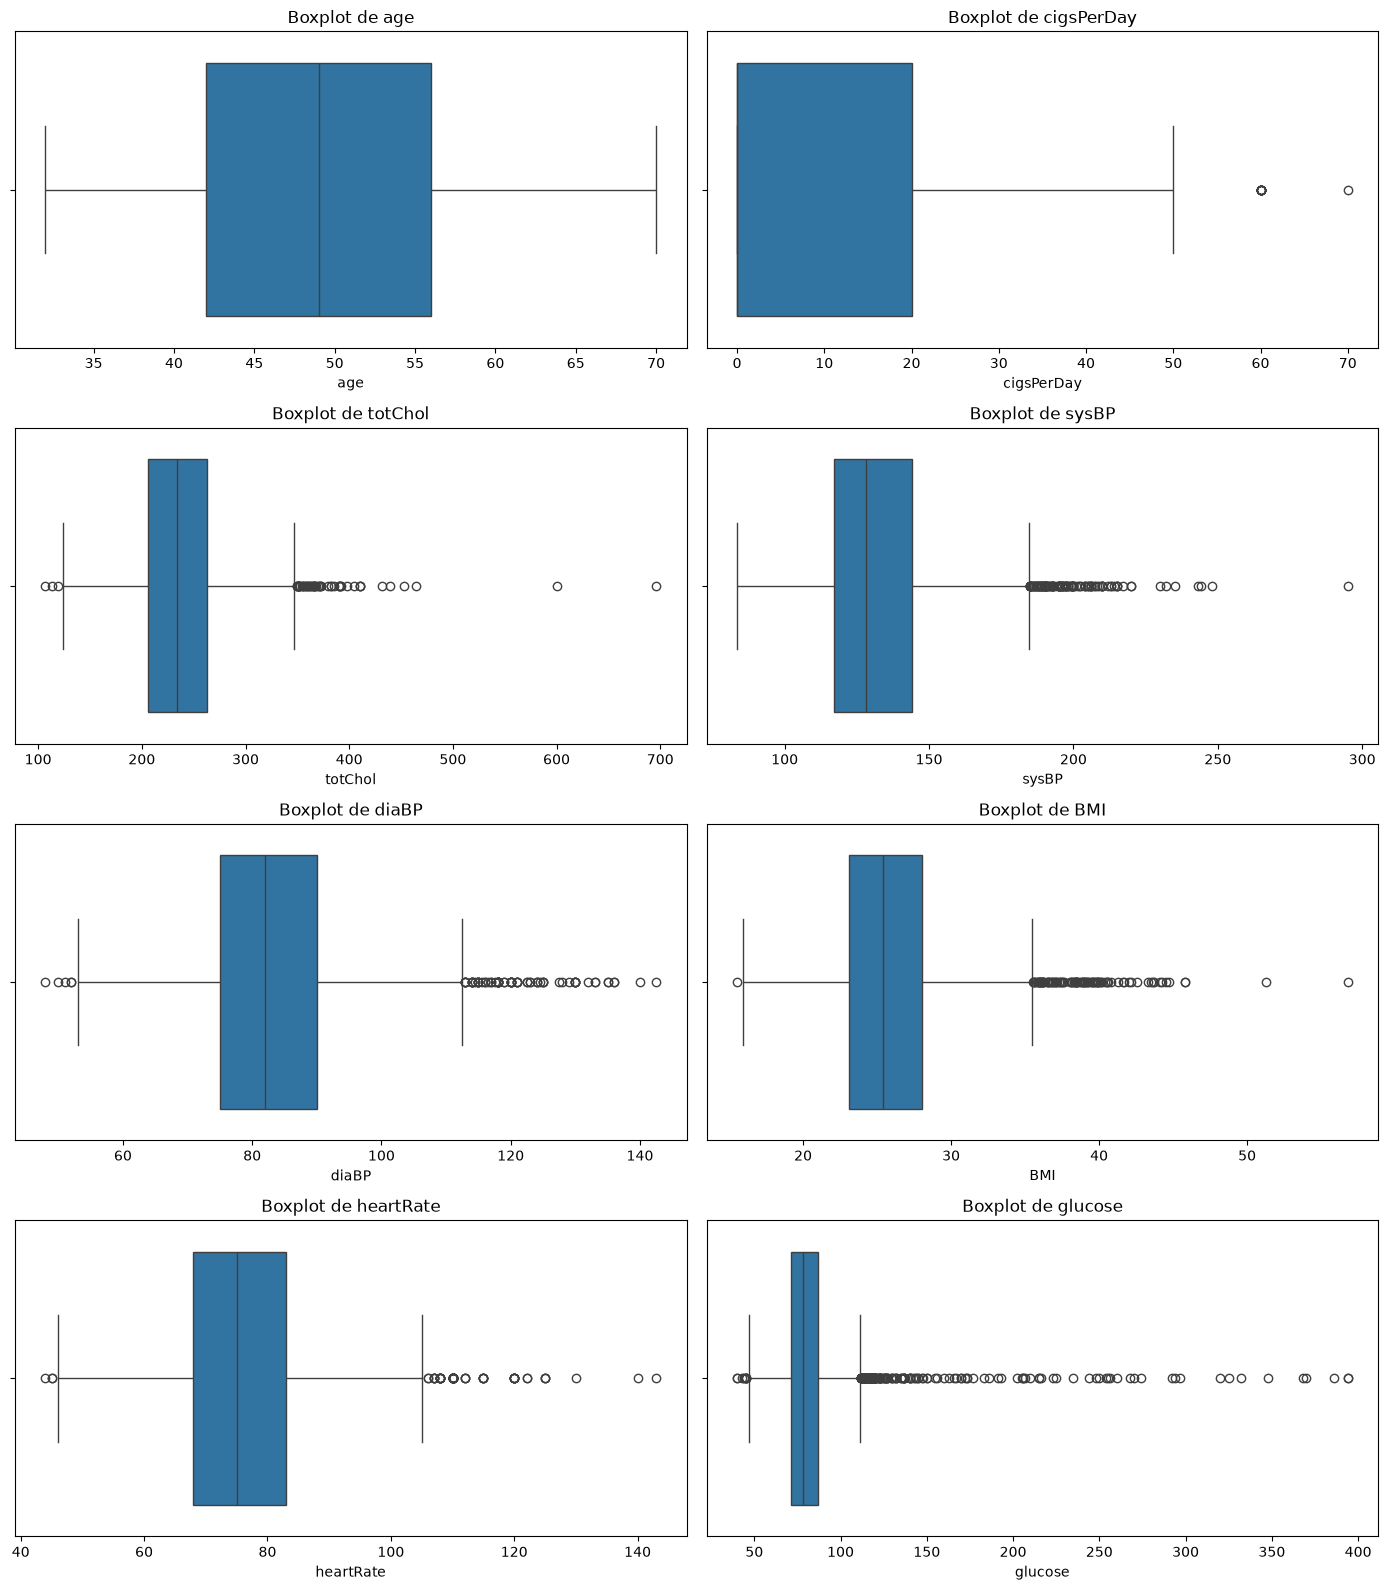

In [10]:
# Boxplots des variables quantitatives
fig, axes = plt.subplots(4, 2, figsize=(14, 16))

for colonne, ax in zip(variables_quantitatives_f, axes.flatten()):
    sns.boxplot(data=data_f, x=colonne, ax=ax)
    ax.set_title(f"Boxplot de {colonne}")

plt.tight_layout()
plt.show()

#### 1.3.2. Variables qualitatives


In [11]:
# Variables qualitatives
variables_qualitatives_f = [
    "male", "education", "currentSmoker",
    "BPMeds", "prevalentStroke",
    "prevalentHyp", "diabetes"
]

# Effectifs et proportions
for colonne in variables_qualitatives_f:
    print(f"\n--- {colonne} ---")
    print(data_f[colonne].value_counts(dropna=False))
    print("\nProportions (%) :")
    print((data_f[colonne].value_counts(normalize=True, dropna=False) * 100).round(2))


--- male ---
male
0    2420
1    1820
Name: count, dtype: int64

Proportions (%) :
male
0    57.08
1    42.92
Name: proportion, dtype: float64

--- education ---
education
1.0    1720
2.0    1253
3.0     689
4.0     473
NaN     105
Name: count, dtype: int64

Proportions (%) :
education
1.0    40.57
2.0    29.55
3.0    16.25
4.0    11.16
NaN     2.48
Name: proportion, dtype: float64

--- currentSmoker ---
currentSmoker
0    2145
1    2095
Name: count, dtype: int64

Proportions (%) :
currentSmoker
0    50.59
1    49.41
Name: proportion, dtype: float64

--- BPMeds ---
BPMeds
0.0    4063
1.0     124
NaN      53
Name: count, dtype: int64

Proportions (%) :
BPMeds
0.0    95.83
1.0     2.92
NaN     1.25
Name: proportion, dtype: float64

--- prevalentStroke ---
prevalentStroke
0    4215
1      25
Name: count, dtype: int64

Proportions (%) :
prevalentStroke
0    99.41
1     0.59
Name: proportion, dtype: float64

--- prevalentHyp ---
prevalentHyp
0    2923
1    1317
Name: count, dtype: int64

P

### Bilan de l'analyse descriptive

L'étude descriptive met en évidence des distributions variées pour les variables quantitatives. L'âge est compris entre 32 et 70 ans, tandis que `cigsPerDay` et `glucose` présentent des distributions asymétriques à droite. Les variables `totChol`, `sysBP`, `diaBP`, `BMI` et `heartRate` comportent également des valeurs potentiellement atypiques, repérées avec la méthode de l'écart interquartile (IQR). Ces observations sont conservées à ce stade : une valeur atypique n'est pas nécessairement une erreur, notamment dans un contexte médical.

Pour les variables qualitatives, certaines modalités sont peu représentées, en particulier les antécédents d'AVC (`prevalentStroke`), le diabète (`diabetes`) et la prise de médicaments contre l'hypertension (`BPMeds`).

Enfin, les valeurs manquantes concernent principalement la glycémie (`glucose`), le niveau d'éducation (`education`) et la prise de médicaments (`BPMeds`). Leur traitement sera intégré au prétraitement des données.


## 2. Étude des relations avec la variable cible

### 2.1. Variables quantitatives

Nous comparons les distributions des variables quantitatives entre les deux groupes de patients : ceux pour lesquels `TenYearCHD = 0` et ceux pour lesquels `TenYearCHD = 1`.


In [12]:
# Variables quantitatives à étudier
variables_quantitatives_f = [
    "age", "cigsPerDay", "totChol", "sysBP",
    "diaBP", "BMI", "heartRate", "glucose"
]

# Comparaison des variables selon TenYearCHD
resultats_groupes_f = []

for colonne in variables_quantitatives_f:

    for classe in [0, 1]:

        valeurs = data_f.loc[
            data_f["TenYearCHD"] == classe, colonne
        ]

        resultats_groupes_f.append({
            "Variable": colonne,
            "TenYearCHD": classe,
            "Effectif": valeurs.count(),
            "Moyenne": valeurs.mean(),
            "Médiane": valeurs.median(),
            "Écart-type": valeurs.std()
        })

table_groupes_f = pd.DataFrame(resultats_groupes_f)

display(table_groupes_f.round(2))

,Variable,TenYearCHD,Effectif,Moyenne,Médiane,Écart-type
0,age,0,3596,48.76,48.00,8.41
1,age,1,644,54.15,55.00,8.01
2,cigsPerDay,0,3569,8.71,0.00,11.69
3,cigsPerDay,1,642,10.63,2.50,13.01
4,totChol,0,3555,235.15,232.00,43.77
5,totChol,1,635,245.39,241.00,48.08
6,sysBP,0,3596,130.34,127.00,20.45
7,sysBP,1,644,143.62,139.00,26.69
8,diaBP,0,3596,82.17,81.00,11.34
9,diaBP,1,644,86.98,85.50,14.03


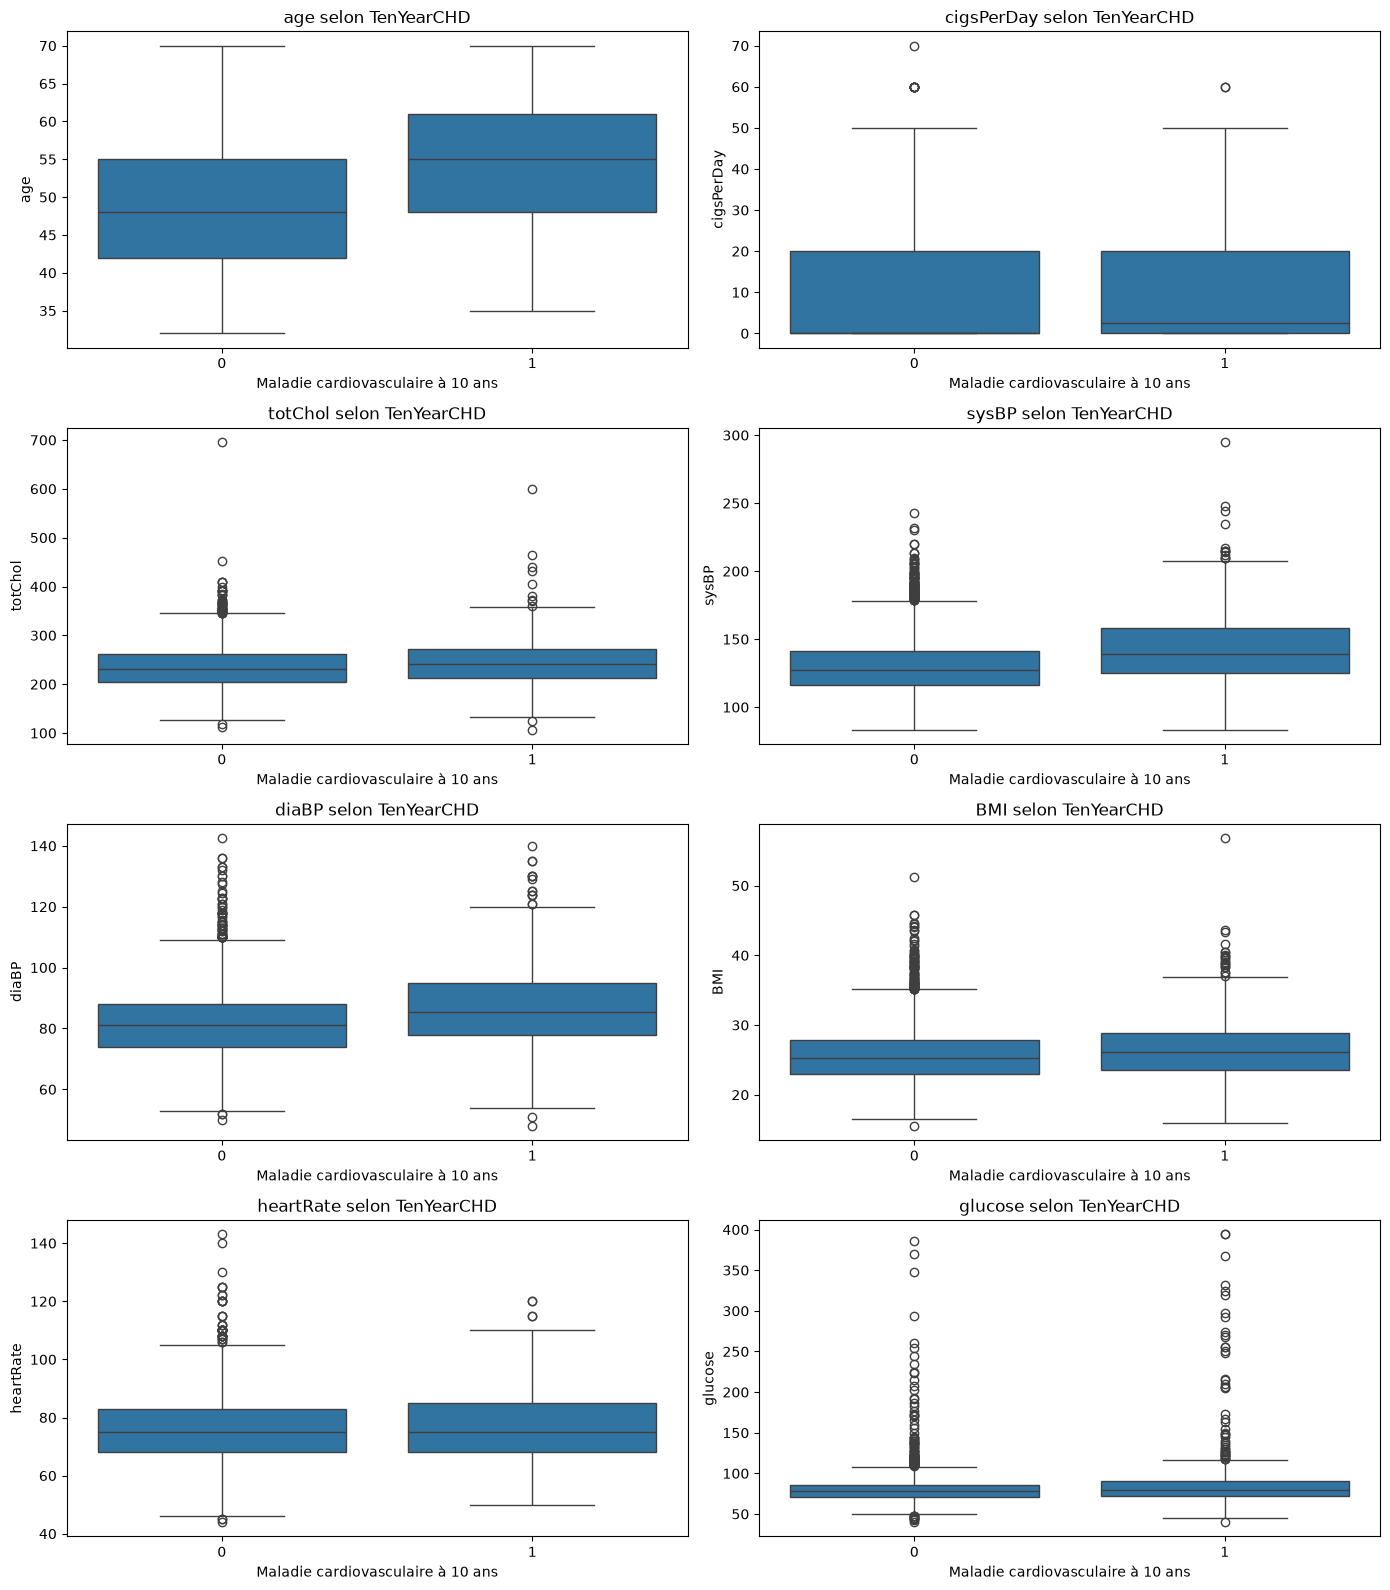

In [13]:
# Boxplots selon la variable cible
fig, axes = plt.subplots(4, 2, figsize=(14, 16))

for colonne, ax in zip(variables_quantitatives_f, axes.flatten()):

    sns.boxplot(
        data=data_f,
        x="TenYearCHD",
        y=colonne,
        ax=ax
    )

    ax.set_title(f"{colonne} selon TenYearCHD")
    ax.set_xlabel("Maladie cardiovasculaire à 10 ans")

plt.tight_layout()
plt.show()

In [14]:
from scipy.stats import mannwhitneyu
# Mann-Whitney permet de comparer les distributions de deux groupes indépendants, surtout lorsque les données ne suivent pas une distribution normale

resultats_mannwhitney_f = []

for colonne in variables_quantitatives_f:

    groupe_0 = data_f.loc[
        data_f["TenYearCHD"] == 0, colonne
    ].dropna()

    groupe_1 = data_f.loc[
        data_f["TenYearCHD"] == 1, colonne
    ].dropna()

    statistique, p_value = mannwhitneyu(
        groupe_0,
        groupe_1,
        alternative="two-sided"
    )

    resultats_mannwhitney_f.append({
        "Variable": colonne,
        "Statistique U": statistique,
        "p-value": p_value
    })

table_mannwhitney_f = pd.DataFrame(resultats_mannwhitney_f)

display(table_mannwhitney_f.round(4))

,Variable,Statistique U,p-value
0,age,742868.0,0.0000
1,cigsPerDay,1071364.0,0.0048
2,totChol,983331.0,0.0000
3,sysBP,795892.5,0.0000
4,diaBP,913051.5,0.0000
5,BMI,1001690.0,0.0000
6,heartRate,1122675.0,0.2411
7,glucose,883551.0,0.0007


### Interprétation des tests de Mann-Whitney

Afin de comparer les distributions des variables quantitatives entre les deux groupes, nous utilisons le test non paramétrique de Mann-Whitney. Le seuil de significativité est fixé à 5 %.

Les résultats mettent en évidence une différence statistiquement significative pour **sept des huit variables** étudiées : l'âge, le nombre de cigarettes fumées par jour, le cholestérol total, les pressions artérielles systolique et diastolique, l'indice de masse corporelle et le taux de glucose (p-value inférieure à 0,05). En revanche, aucune différence significative n'est observée pour le rythme cardiaque (`heartRate`, p = 0,2411).

Les patients ayant développé une maladie coronarienne présentent notamment un âge médian plus élevé (55 ans contre 48 ans), ainsi que des médianes plus élevées pour le cholestérol total (241 contre 232) et les pressions artérielles systolique (139 contre 127) et diastolique (85,5 contre 81). Ces résultats décrivent des associations observées dans les données ; ils ne permettent pas de conclure à un lien causal ni d'isoler l'effet propre de chaque variable.

### 2.2. Variables qualitatives


In [15]:
variables_qualitatives_f = [
    "male", "education", "currentSmoker",
    "BPMeds", "prevalentStroke",
    "prevalentHyp", "diabetes"
]

for colonne in variables_qualitatives_f:

    print(f"\n--- {colonne} ---")

    tableau = pd.crosstab(
        data_f[colonne],
        data_f["TenYearCHD"],
        normalize="index"
    ) * 100

    tableau.columns = [
        "Sans maladie (%)",
        "Avec maladie (%)"
    ]

    print(tableau.round(2))


--- male ---
      Sans maladie (%)  Avec maladie (%)
male                                    
0                87.56             12.44
1                81.15             18.85

--- education ---
           Sans maladie (%)  Avec maladie (%)
education                                    
1.0                   81.22             18.78
2.0                   88.27             11.73
3.0                   87.23             12.77
4.0                   85.20             14.80

--- currentSmoker ---
               Sans maladie (%)  Avec maladie (%)
currentSmoker                                    
0                         85.50             14.50
1                         84.11             15.89

--- BPMeds ---
        Sans maladie (%)  Avec maladie (%)
BPMeds                                    
0.0                85.43             14.57
1.0                66.94             33.06

--- prevalentStroke ---
                 Sans maladie (%)  Avec maladie (%)
prevalentStroke                        

Les tableaux ci-dessous permettent de comparer, pour chaque modalité, la proportion de patients ayant ou non développé une maladie coronarienne.

Quelques écarts descriptifs apparaissent, notamment pour le sexe, les antécédents d'AVC, l'hypertension, le diabète et la prise de médicaments contre l'hypertension. Ces différences doivent toutefois être interprétées en tenant compte des effectifs de chaque modalité.


In [16]:
from scipy.stats import chi2_contingency
import numpy as np

variables_qualitatives_f = [
    "male", "education", "currentSmoker",
    "BPMeds", "prevalentStroke",
    "prevalentHyp", "diabetes"
]

resultats_tests_f = []

for colonne in variables_qualitatives_f:

    # Tableau de contingence, sans les valeurs manquantes
    tableau = pd.crosstab(
        data_f[colonne],
        data_f["TenYearCHD"]
    )

    # Test du Khi-deux
    chi2, p_value, ddl, effectifs_theoriques = chi2_contingency(tableau)

    # Calcul du V de Cramér
    n = tableau.to_numpy().sum()
    min_dim = min(tableau.shape[0] - 1, tableau.shape[1] - 1)

    cramers_v = np.sqrt(chi2 / (n * min_dim))

    resultats_tests_f.append({
        "Variable": colonne,
        "Khi-deux": chi2,
        "Degrés de liberté": ddl,
        "p-value": p_value,
        "V de Cramér": cramers_v
    })

table_tests_f = pd.DataFrame(resultats_tests_f)

display(table_tests_f.round(4))

,Variable,Khi-deux,Degrés de liberté,p-value,V de Cramér
0,male,32.6183,1,0.0000,0.0877
1,education,32.0170,3,0.0000,0.0880
2,currentSmoker,1.4972,1,0.2211,0.0188
3,BPMeds,30.6460,1,0.0000,0.0856
4,prevalentStroke,14.0337,1,0.0002,0.0575
5,prevalentHyp,132.4563,1,0.0000,0.1767
6,diabetes,38.4823,1,0.0000,0.0953


In [17]:
# Vérification des effectifs théoriques du Khi-deux

for colonne in variables_qualitatives_f:

    tableau = pd.crosstab(
        data_f[colonne],
        data_f["TenYearCHD"]
    )

    chi2, p_value, ddl, effectifs_theoriques = chi2_contingency(tableau)

    print(f"\n--- {colonne} ---")
    print(pd.DataFrame(
        effectifs_theoriques,
        index=tableau.index,
        columns=tableau.columns
    ).round(2))

    print(
        "Nombre de cases avec un effectif théorique inférieur à 5 :",
        (effectifs_theoriques < 5).sum()
    )


--- male ---
TenYearCHD        0       1
male                       
0           2052.43  367.57
1           1543.57  276.43
Nombre de cases avec un effectif théorique inférieur à 5 : 0

--- education ---
TenYearCHD        0       1
education                  
1.0         1458.78  261.22
2.0         1062.70  190.30
3.0          584.36  104.64
4.0          401.16   71.84
Nombre de cases avec un effectif théorique inférieur à 5 : 0

--- currentSmoker ---
TenYearCHD          0      1
currentSmoker               
0              1819.2  325.8
1              1776.8  318.2
Nombre de cases avec un effectif théorique inférieur à 5 : 0

--- BPMeds ---
TenYearCHD        0       1
BPMeds                     
0.0         3448.75  614.25
1.0          105.25   18.75
Nombre de cases avec un effectif théorique inférieur à 5 : 0

--- prevalentStroke ---
TenYearCHD            0      1
prevalentStroke               
0                3574.8  640.2
1                  21.2    3.8
Nombre de cases avec un eff

### Interprétation du test du Khi-deux et du V de Cramér

Le test du Khi-deux et le V de Cramér permettent respectivement d'évaluer l'existence et l'intensité d'une association entre chaque variable qualitative et `TenYearCHD`.

Les résultats mettent en évidence une association statistiquement significative pour **six des sept variables** étudiées. Les variables `male`, `education`, `BPMeds`, `prevalentStroke`, `prevalentHyp` et `diabetes` présentent une p-value inférieure à 0,05. En revanche, aucune association statistiquement significative n'est mise en évidence pour le statut de fumeur actuel (`currentSmoker`, p = 0,2211).

L'association la plus forte concerne l'hypertension (`prevalentHyp`), avec un V de Cramér de **0,1767**. Les autres associations sont faibles (V de Cramér compris entre 0,0575 et 0,0953). Pour `prevalentStroke`, une case du tableau présente un effectif théorique inférieur à 5 ; le résultat doit donc être interprété avec prudence.

### 2.3. Matrice de corrélation


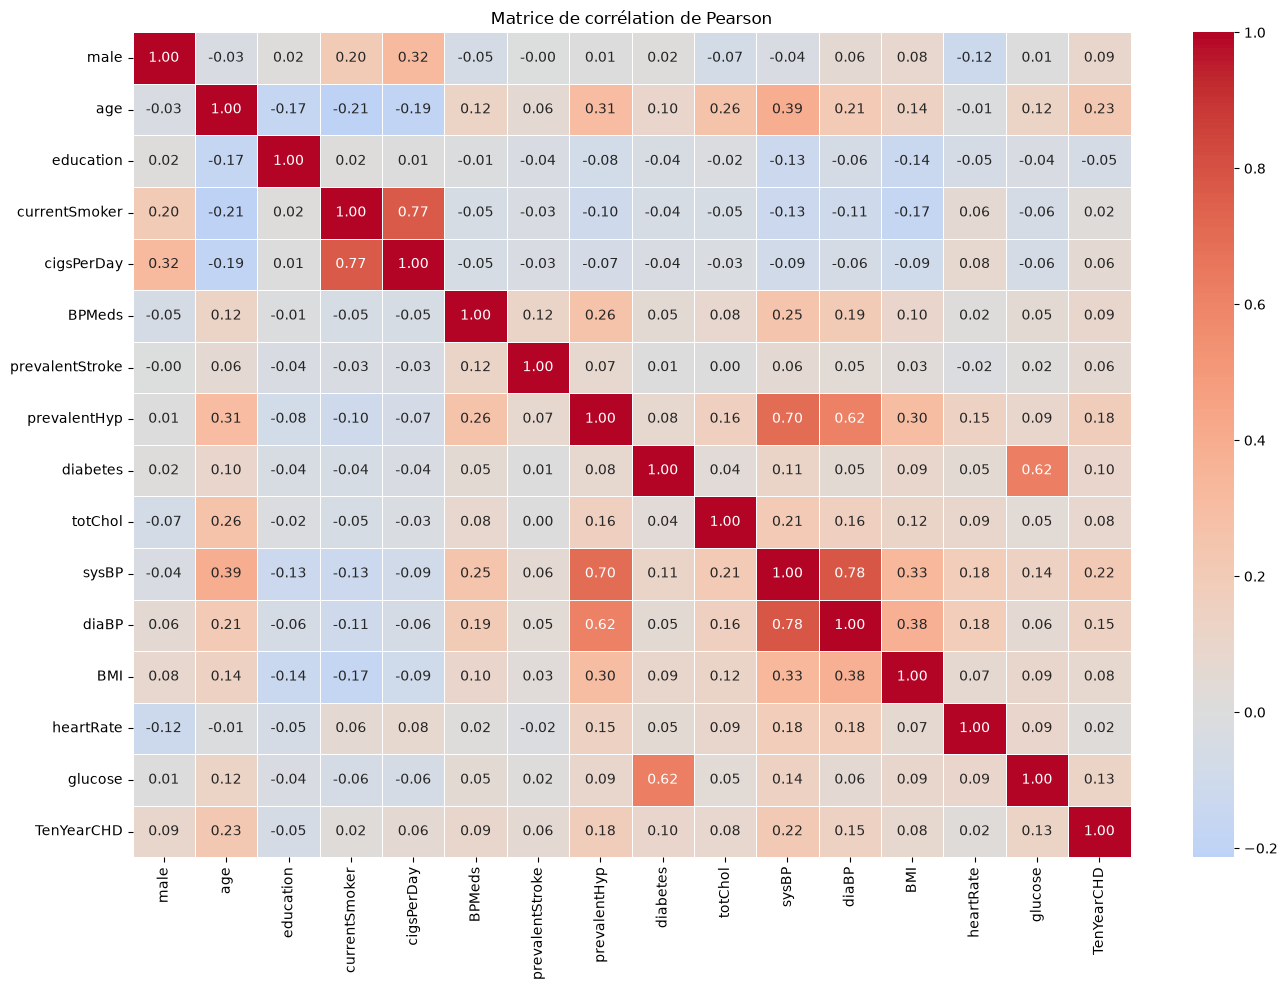

In [18]:
# Calcul de la matrice de corrélation
matrice_corr_f = data_f.corr(method="pearson")

# Affichage de la matrice sous forme de heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    matrice_corr_f,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Matrice de corrélation de Pearson")
plt.tight_layout()
plt.show()

## 3. Prétraitement des données

### 3.1. Séparation en jeux d'entraînement et de test


In [19]:
from sklearn.model_selection import train_test_split

# Séparation des variables explicatives et de la variable cible
X_f = data_f.drop(columns=["TenYearCHD"])
y_f = data_f["TenYearCHD"]

# Séparation en jeu d'entraînement (80 %) et jeu de test (20 %)
X_train_f, X_test_f, y_train_f, y_test_f = train_test_split(
    X_f,
    y_f,
    test_size=0.2,
    random_state=42,
    stratify=y_f
)

print("Taille de X_train :", X_train_f.shape)
print("Taille de X_test :", X_test_f.shape)

print("\nRépartition de la cible dans le jeu d'entraînement :")
print(y_train_f.value_counts(normalize=True))

print("\nRépartition de la cible dans le jeu de test :")
print(y_test_f.value_counts(normalize=True))

Taille de X_train : (3392, 15)
Taille de X_test : (848, 15)

Répartition de la cible dans le jeu d'entraînement :
TenYearCHD
0    0.848172
1    0.151828
Name: proportion, dtype: float64

Répartition de la cible dans le jeu de test :
TenYearCHD
0    0.847877
1    0.152123
Name: proportion, dtype: float64


### 3.2. Imputation des valeurs manquantes et standardisation

582 lignes (13,73 % du jeu de données) comportent au moins une valeur manquante. Plutôt que de supprimer toutes ces observations, nous choisissons d'imputer les valeurs manquantes :

- par la **médiane** pour les variables quantitatives ;
- par la **valeur la plus fréquente** pour les variables qualitatives.

Les variables quantitatives sont ensuite standardisées à l'aide de `StandardScaler`. Le préprocesseur est ajusté uniquement sur le jeu d'entraînement, puis appliqué au jeu de test sans nouvel ajustement.


In [20]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Définition des groupes de variables
variables_quantitatives_f = [
    "age", "cigsPerDay", "totChol", "sysBP",
    "diaBP", "BMI", "heartRate", "glucose"
]

variables_categorielles_f = [
    "male", "education", "currentSmoker",
    "BPMeds", "prevalentStroke", "prevalentHyp", "diabetes"
]

# Pipeline pour les variables quantitatives
pipeline_quant_f = Pipeline([
    ("imputation", SimpleImputer(strategy="median")),
    ("standardisation", StandardScaler())
])

# Pipeline pour les variables catégorielles
pipeline_cat_f = Pipeline([
    ("imputation", SimpleImputer(strategy="most_frequent"))
])

# Préprocesseur global
process_f = ColumnTransformer([
    ("quantitatives", pipeline_quant_f, variables_quantitatives_f),
    ("categorielles", pipeline_cat_f, variables_categorielles_f)
])

# Apprentissage du préprocesseur sur le jeu d'entraînement uniquement
X_train_f_prepared = process_f.fit_transform(X_train_f)

# Application du préprocesseur au jeu de test
X_test_f_prepared = process_f.transform(X_test_f)

print("Dimensions de X_train préparé :", X_train_f_prepared.shape)
print("Dimensions de X_test préparé :", X_test_f_prepared.shape)

Dimensions de X_train préparé : (3392, 15)
Dimensions de X_test préparé : (848, 15)


In [21]:
# Vérification des valeurs manquantes
print("Valeurs manquantes dans X_train :",
      np.isnan(X_train_f_prepared).sum())

print("Valeurs manquantes dans X_test :",
      np.isnan(X_test_f_prepared).sum())

# Répartition des classes
print("\nRépartition dans le jeu d'entraînement :")
print(y_train_f.value_counts())
print(y_train_f.value_counts(normalize=True) * 100)

print("\nRépartition dans le jeu de test :")
print(y_test_f.value_counts())
print(y_test_f.value_counts(normalize=True) * 100)

Valeurs manquantes dans X_train : 0
Valeurs manquantes dans X_test : 0

Répartition dans le jeu d'entraînement :
TenYearCHD
0    2877
1     515
Name: count, dtype: int64
TenYearCHD
0    84.817217
1    15.182783
Name: proportion, dtype: float64

Répartition dans le jeu de test :
TenYearCHD
0    719
1    129
Name: count, dtype: int64
TenYearCHD
0    84.787736
1    15.212264
Name: proportion, dtype: float64


## 4. Modélisation exploratoire

Nous comparons plusieurs algorithmes de classification. Compte tenu du déséquilibre de la variable cible, nous examinons plusieurs métriques : la précision (*precision*), le rappel (*recall*), le F1-score et la ROC-AUC, en complément de l'accuracy.

**Précaution méthodologique :** les premières comparaisons de cette section utilisent le jeu de test pour explorer les performances des modèles. Ces résultats sont donc exploratoires et ne constituent pas une évaluation finale indépendante. La sélection finale du seuil est ensuite réalisée sur un jeu de validation.


In [22]:
### Métriques d'évaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [23]:
# Fonction pour étudier plusieurs seuils de décision
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, recall_score, f1_score, precision_score

seuils_f = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

def explorer_seuils_f(y_reel, probabilites, nom_modele):
    """Calcule les métriques pour chaque seuil et affiche leur évolution."""
    resultats = []

    for seuil in seuils_f:
        predictions = (probabilites >= seuil).astype(int)
        resultats.append({
            "Seuil": seuil,
            "Accuracy": accuracy_score(y_reel, predictions),
            "Precision": precision_score(y_reel, predictions, zero_division=0),
            "Recall": recall_score(y_reel, predictions, zero_division=0),
            "F1-score": f1_score(y_reel, predictions, zero_division=0)
        })

    resultats_seuils = pd.DataFrame(resultats)
    display(resultats_seuils.round(3))

    meilleur = resultats_seuils.loc[resultats_seuils["F1-score"].idxmax()]
    print(f"Meilleur F1-score : {meilleur['F1-score']:.3f} pour le seuil {meilleur['Seuil']:.2f}")

    plt.figure(figsize=(9, 5))
    plt.plot(resultats_seuils["Seuil"], resultats_seuils["Accuracy"], marker="o", label="Accuracy")
    plt.plot(resultats_seuils["Seuil"], resultats_seuils["Recall"], marker="o", label="Recall")
    plt.plot(resultats_seuils["Seuil"], resultats_seuils["F1-score"], marker="o", label="F1-score")
    plt.axvline(meilleur["Seuil"], color="grey", linestyle="--",
                label=f"Meilleur seuil F1 = {meilleur['Seuil']:.2f}")
    plt.xlabel("Seuil de décision")
    plt.ylabel("Score")
    plt.title(f"Évolution des métriques selon le seuil — {nom_modele}")
    plt.xticks(seuils_f, rotation=45)
    plt.ylim(0, 1)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()


### 4.1. Régression logistique


In [24]:
from sklearn.linear_model import LogisticRegression

# Création du modèle
modele_logistique_f = LogisticRegression(
    random_state=42,
    max_iter=1000
)

# Entraînement
modele_logistique_f.fit(X_train_f_prepared, y_train_f)

# Prédictions sur le jeu de test
y_pred_log_f = modele_logistique_f.predict(X_test_f_prepared)

# Probabilités prédites pour la classe 1
y_proba_log_f = modele_logistique_f.predict_proba(X_test_f_prepared)[:, 1]

print("Accuracy :", accuracy_score(y_test_f, y_pred_log_f))
print("Precision :", precision_score(y_test_f, y_pred_log_f))
print("Recall :", recall_score(y_test_f, y_pred_log_f))
print("F1-score :", f1_score(y_test_f, y_pred_log_f))
print("ROC-AUC :", roc_auc_score(y_test_f, y_proba_log_f))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test_f, y_pred_log_f))

print("\nRapport de classification :")
print(classification_report(y_test_f, y_pred_log_f))

Accuracy : 0.8443396226415094
Precision : 0.4117647058823529
Recall : 0.05426356589147287
F1-score : 0.0958904109589041
ROC-AUC : 0.7023751765479618

Matrice de confusion :
[[709  10]
 [122   7]]

Rapport de classification :
              precision    recall  f1-score   support

           0       0.85      0.99      0.91       719
           1       0.41      0.05      0.10       129

    accuracy                           0.84       848
   macro avg       0.63      0.52      0.51       848
weighted avg       0.79      0.84      0.79       848



,Seuil,Accuracy,Precision,Recall,F1-score
0,0.10,0.546,0.223,0.798,0.349
1,0.15,0.670,0.257,0.620,0.364
2,0.20,0.741,0.278,0.442,0.341
3,0.25,0.785,0.317,0.357,0.336
4,0.30,0.810,0.340,0.264,0.297
5,0.35,0.820,0.306,0.147,0.199
6,0.40,0.836,0.368,0.109,0.168
7,0.45,0.838,0.346,0.070,0.116
8,0.50,0.844,0.412,0.054,0.096
9,0.55,0.847,0.455,0.039,0.071


Meilleur F1-score : 0.364 pour le seuil 0.15


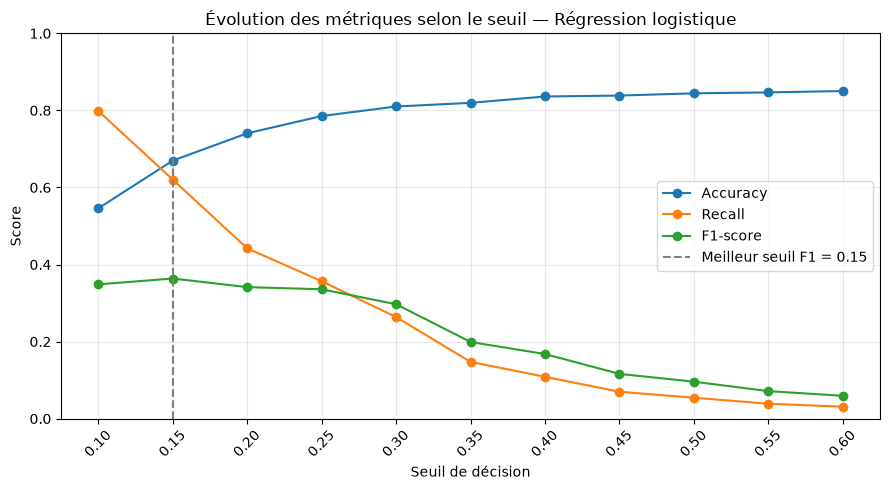

In [25]:
explorer_seuils_f(y_test_f, y_proba_log_f, "Régression logistique")

Au seuil par défaut (0,5), la régression logistique obtient une accuracy de **84,4 %** et une ROC-AUC de **0,702**, mais son rappel est très faible (**5,4 %**) : elle ne détecte que 7 des 129 patients positifs.

L'exploration des seuils améliore nettement le F1-score. Le meilleur résultat parmi les seuils testés est de **0,364 pour un seuil de 0,15**, avec une accuracy de 67,0 % et un rappel de 62,0 %. La baisse du seuil permet donc de mieux repérer les patients positifs, mais augmente le nombre de faux positifs.

In [26]:
# Régression logistique avec pondération des classes
modele_log_bal_f = LogisticRegression(
    random_state=42,
    max_iter=1000,
    class_weight="balanced"
)

# Entraînement
modele_log_bal_f.fit(X_train_f_prepared, y_train_f)

# Prédictions
y_pred_log_bal_f = modele_log_bal_f.predict(X_test_f_prepared)
y_proba_log_bal_f = modele_log_bal_f.predict_proba(X_test_f_prepared)[:, 1]

# Évaluation
print("Accuracy :", accuracy_score(y_test_f, y_pred_log_bal_f))
print("Precision :", precision_score(y_test_f, y_pred_log_bal_f))
print("Recall :", recall_score(y_test_f, y_pred_log_bal_f))
print("F1-score :", f1_score(y_test_f, y_pred_log_bal_f))
print("ROC-AUC :", roc_auc_score(y_test_f, y_proba_log_bal_f))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test_f, y_pred_log_bal_f))

print("\nRapport de classification :")
print(classification_report(y_test_f, y_pred_log_bal_f))

Accuracy : 0.6709905660377359
Precision : 0.2549019607843137
Recall : 0.6046511627906976
F1-score : 0.3586206896551724
ROC-AUC : 0.700628564651594

Matrice de confusion :
[[491 228]
 [ 51  78]]

Rapport de classification :
              precision    recall  f1-score   support

           0       0.91      0.68      0.78       719
           1       0.25      0.60      0.36       129

    accuracy                           0.67       848
   macro avg       0.58      0.64      0.57       848
weighted avg       0.81      0.67      0.71       848



,Seuil,Accuracy,Precision,Recall,F1-score
0,0.10,0.165,0.153,0.992,0.266
1,0.15,0.212,0.161,0.992,0.277
2,0.20,0.278,0.169,0.953,0.287
3,0.25,0.344,0.179,0.922,0.300
4,0.30,0.436,0.199,0.891,0.325
5,0.35,0.515,0.220,0.860,0.351
6,0.40,0.564,0.226,0.767,0.349
7,0.45,0.614,0.235,0.682,0.350
8,0.50,0.671,0.255,0.605,0.359
9,0.55,0.718,0.275,0.519,0.359


Meilleur F1-score : 0.359 pour le seuil 0.55


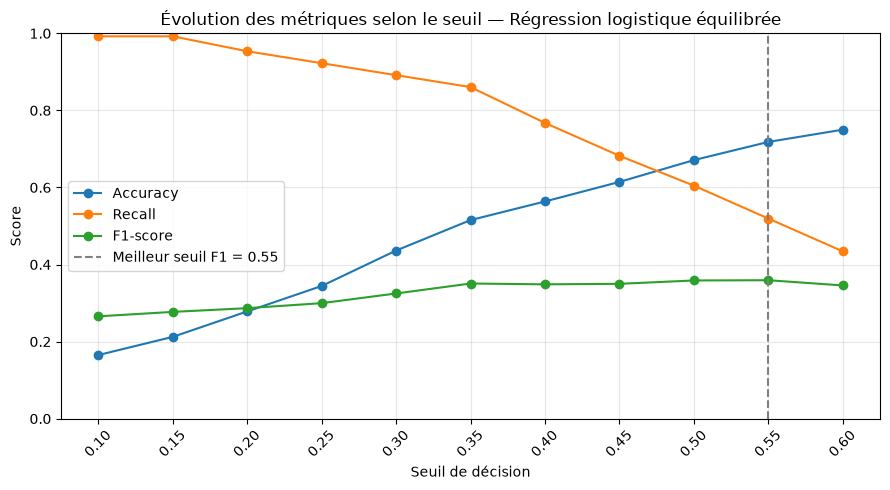

In [27]:
explorer_seuils_f(y_test_f, y_proba_log_bal_f, "Régression logistique équilibrée")

Avec `class_weight="balanced"` et le seuil par défaut (0,5), le rappel atteint **60,5 %**, mais la précision reste limitée à **25,5 %** ; le F1-score est de 0,359.

L'exploration des seuils donne un meilleur F1-score de **0,359 pour un seuil de 0,55**. Ce résultat est légèrement inférieur à celui de la régression logistique sans pondération (0,364). La pondération améliore donc fortement la détection des cas positifs par rapport au modèle initial, mais elle n'est pas la stratégie la plus performante selon le F1-score exploratoire.

### 4.2. SVM avec noyau RBF


In [28]:
from sklearn.svm import SVC

# Création du modèle SVM
modele_svm_f = SVC(
    kernel="rbf",
    probability=True,
    random_state=42
)

# Entraînement
modele_svm_f.fit(X_train_f_prepared, y_train_f)

# Prédictions
y_pred_svm_f = modele_svm_f.predict(X_test_f_prepared)
y_proba_svm_f = modele_svm_f.predict_proba(X_test_f_prepared)[:, 1]

# Évaluation
print("Accuracy :", accuracy_score(y_test_f, y_pred_svm_f))
print("Precision :", precision_score(y_test_f, y_pred_svm_f))
print("Recall :", recall_score(y_test_f, y_pred_svm_f))
print("F1-score :", f1_score(y_test_f, y_pred_svm_f))
print("ROC-AUC :", roc_auc_score(y_test_f, y_proba_svm_f))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test_f, y_pred_svm_f))

print("\nRapport de classification :")
print(classification_report(y_test_f, y_pred_svm_f))

c:\Users\gilbe\Documents\AgroParisTech\3A\VG\MachineLearning\Projet\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Accuracy : 0.8525943396226415
Precision : 1.0
Recall : 0.031007751937984496
F1-score : 0.06015037593984962
ROC-AUC : 0.5316384729005617

Matrice de confusion :
[[719   0]
 [125   4]]

Rapport de classification :
              precision    recall  f1-score   support

           0       0.85      1.00      0.92       719
           1       1.00      0.03      0.06       129

    accuracy                           0.85       848
   macro avg       0.93      0.52      0.49       848
weighted avg       0.87      0.85      0.79       848



,Seuil,Accuracy,Precision,Recall,F1-score
0,0.10,0.158,0.152,0.992,0.264
1,0.15,0.764,0.241,0.256,0.248
2,0.20,0.820,0.293,0.132,0.182
3,0.25,0.829,0.310,0.101,0.152
4,0.30,0.837,0.345,0.078,0.127
5,0.35,0.837,0.333,0.070,0.115
6,0.40,0.840,0.348,0.062,0.105
7,0.45,0.842,0.368,0.054,0.095
8,0.50,0.844,0.412,0.054,0.096
9,0.55,0.847,0.462,0.047,0.085


Meilleur F1-score : 0.264 pour le seuil 0.10


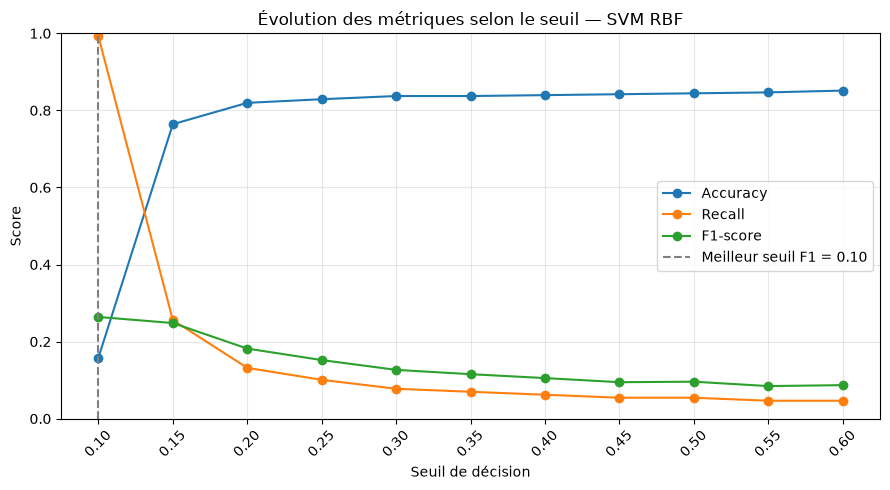

In [29]:
explorer_seuils_f(y_test_f, y_proba_svm_f, "SVM RBF")

Au seuil par défaut, le SVM obtient une accuracy de **85,3 %**, mais son rappel est très faible (**3,1 %**) : seuls 4 des 129 patients positifs sont détectés. Son F1-score est de 0,060 et sa ROC-AUC de 0,532.

L'exploration des seuils améliore son F1-score jusqu'à **0,264 au seuil de 0,10**. Ce seuil permet de détecter presque tous les patients positifs (rappel de 99,2 %), mais au prix d'une très forte diminution de l'accuracy (15,8 %) et d'une faible précision. Le SVM présente donc un compromis peu satisfaisant par rapport aux meilleurs modèles.

### 4.3. Arbre de décision


In [30]:
from sklearn.tree import DecisionTreeClassifier

# Création du modèle
modele_arbre_f = DecisionTreeClassifier(
    random_state=42
)

# Entraînement
modele_arbre_f.fit(X_train_f_prepared, y_train_f)

# Prédictions
y_pred_arbre_f = modele_arbre_f.predict(X_test_f_prepared)
y_proba_arbre_f = modele_arbre_f.predict_proba(X_test_f_prepared)[:, 1]

# Évaluation
print("Accuracy :", accuracy_score(y_test_f, y_pred_arbre_f))
print("Precision :", precision_score(y_test_f, y_pred_arbre_f))
print("Recall :", recall_score(y_test_f, y_pred_arbre_f))
print("F1-score :", f1_score(y_test_f, y_pred_arbre_f))
print("ROC-AUC :", roc_auc_score(y_test_f, y_proba_arbre_f))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test_f, y_pred_arbre_f))

print("\nRapport de classification :")
print(classification_report(y_test_f, y_pred_arbre_f))

Accuracy : 0.7606132075471698
Precision : 0.20161290322580644
Recall : 0.1937984496124031
F1-score : 0.1976284584980237
ROC-AUC : 0.5280536058910416

Matrice de confusion :
[[620  99]
 [104  25]]

Rapport de classification :
              precision    recall  f1-score   support

           0       0.86      0.86      0.86       719
           1       0.20      0.19      0.20       129

    accuracy                           0.76       848
   macro avg       0.53      0.53      0.53       848
weighted avg       0.76      0.76      0.76       848



,Seuil,Accuracy,Precision,Recall,F1-score
0,0.10,0.761,0.202,0.194,0.198
1,0.15,0.761,0.202,0.194,0.198
2,0.20,0.761,0.202,0.194,0.198
3,0.25,0.761,0.202,0.194,0.198
4,0.30,0.761,0.202,0.194,0.198
5,0.35,0.761,0.202,0.194,0.198
6,0.40,0.761,0.202,0.194,0.198
7,0.45,0.761,0.202,0.194,0.198
8,0.50,0.761,0.202,0.194,0.198
9,0.55,0.761,0.202,0.194,0.198


Meilleur F1-score : 0.198 pour le seuil 0.10


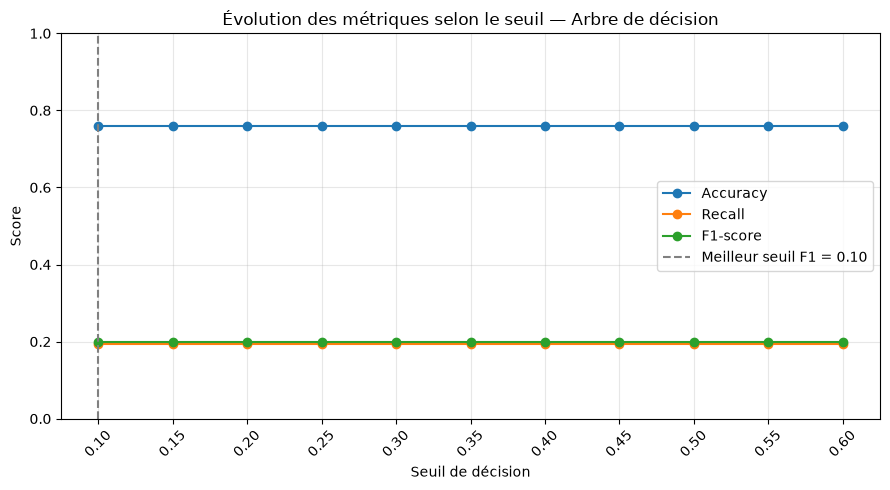

In [31]:
explorer_seuils_f(y_test_f, y_proba_arbre_f, "Arbre de décision")

Au seuil par défaut, l'arbre de décision obtient une accuracy de **76,1 %**, une précision de 20,2 % et un rappel de 19,4 %. Il détecte ainsi 25 des 129 patients positifs.

L'exploration des seuils ne modifie pas ses prédictions : son meilleur F1-score reste de **0,198**, quel que soit le seuil testé entre 0,10 et 0,60. Il s'agit du score le plus faible parmi les modèles comparés.

### 4.4. Random Forest


In [32]:
from sklearn.ensemble import RandomForestClassifier

# Création du modèle
modele_rf_f = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Entraînement
modele_rf_f.fit(X_train_f_prepared, y_train_f)

# Prédictions
y_pred_rf_f = modele_rf_f.predict(X_test_f_prepared)
y_proba_rf_f = modele_rf_f.predict_proba(X_test_f_prepared)[:, 1]

# Évaluation
print("Accuracy :", accuracy_score(y_test_f, y_pred_rf_f))
print("Precision :", precision_score(y_test_f, y_pred_rf_f))
print("Recall :", recall_score(y_test_f, y_pred_rf_f))
print("F1-score :", f1_score(y_test_f, y_pred_rf_f))
print("ROC-AUC :", roc_auc_score(y_test_f, y_proba_rf_f))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test_f, y_pred_rf_f))

print("\nRapport de classification :")
print(classification_report(y_test_f, y_pred_rf_f))

# Conserver les probabilités de la Random Forest initiale
y_proba_rf_initial_f = y_proba_rf_f


Accuracy : 0.847877358490566
Precision : 0.5
Recall : 0.05426356589147287
F1-score : 0.0979020979020979
ROC-AUC : 0.6375834222811615

Matrice de confusion :
[[712   7]
 [122   7]]

Rapport de classification :
              precision    recall  f1-score   support

           0       0.85      0.99      0.92       719
           1       0.50      0.05      0.10       129

    accuracy                           0.85       848
   macro avg       0.68      0.52      0.51       848
weighted avg       0.80      0.85      0.79       848



,Seuil,Accuracy,Precision,Recall,F1-score
0,0.10,0.486,0.197,0.775,0.314
1,0.15,0.586,0.200,0.574,0.297
2,0.20,0.673,0.218,0.442,0.292
3,0.25,0.752,0.260,0.341,0.295
4,0.30,0.785,0.261,0.225,0.242
5,0.35,0.809,0.274,0.155,0.198
6,0.40,0.827,0.312,0.116,0.169
7,0.45,0.838,0.375,0.093,0.149
8,0.50,0.847,0.474,0.070,0.122
9,0.55,0.848,0.500,0.039,0.072


Meilleur F1-score : 0.314 pour le seuil 0.10


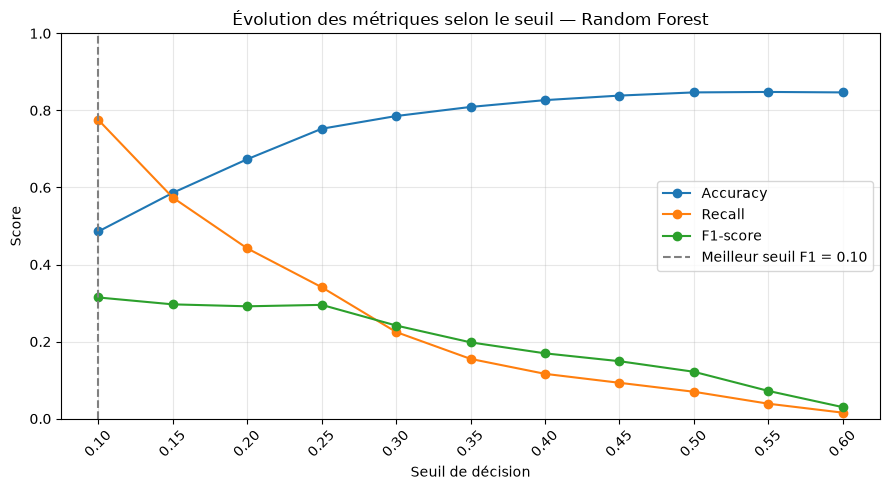

In [33]:
explorer_seuils_f(y_test_f, y_proba_rf_initial_f, "Random Forest")

Au seuil par défaut, la Random Forest obtient une accuracy de **84,8 %**, mais son rappel est très faible (**5,4 %**) et son F1-score vaut 0,098.

L'exploration des seuils améliore son meilleur F1-score jusqu'à **0,314 au seuil de 0,10**. Le rappel atteint alors 77,5 %, mais l'accuracy diminue à 48,6 % et la précision à 19,7 %. La baisse du seuil favorise donc la détection des patients positifs, avec une augmentation importante des faux positifs.

In [34]:
from sklearn.ensemble import RandomForestClassifier

# Création du modèle
modele_rf_f = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    class_weight='balanced'
)

# Entraînement
modele_rf_f.fit(X_train_f_prepared, y_train_f)

# Prédictions
y_pred_rf_f = modele_rf_f.predict(X_test_f_prepared)
y_proba_rf_f = modele_rf_f.predict_proba(X_test_f_prepared)[:, 1]

# Évaluation
print("Accuracy :", accuracy_score(y_test_f, y_pred_rf_f))
print("Precision :", precision_score(y_test_f, y_pred_rf_f))
print("Recall :", recall_score(y_test_f, y_pred_rf_f))
print("F1-score :", f1_score(y_test_f, y_pred_rf_f))
print("ROC-AUC :", roc_auc_score(y_test_f, y_proba_rf_f))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test_f, y_pred_rf_f))

print("\nRapport de classification :")
print(classification_report(y_test_f, y_pred_rf_f))

# Conserver les probabilités de la Random Forest équilibrée
y_proba_rf_bal_f = y_proba_rf_f


Accuracy : 0.8113207547169812
Precision : 0.2876712328767123
Recall : 0.16279069767441862
F1-score : 0.2079207920792079
ROC-AUC : 0.6468717318411661

Matrice de confusion :
[[667  52]
 [108  21]]

Rapport de classification :
              precision    recall  f1-score   support

           0       0.86      0.93      0.89       719
           1       0.29      0.16      0.21       129

    accuracy                           0.81       848
   macro avg       0.57      0.55      0.55       848
weighted avg       0.77      0.81      0.79       848



,Seuil,Accuracy,Precision,Recall,F1-score
0,0.10,0.301,0.169,0.915,0.285
1,0.15,0.403,0.184,0.853,0.303
2,0.20,0.520,0.206,0.752,0.323
3,0.25,0.596,0.218,0.643,0.326
4,0.30,0.650,0.227,0.543,0.320
5,0.35,0.691,0.226,0.426,0.296
6,0.40,0.738,0.237,0.326,0.275
7,0.45,0.774,0.256,0.256,0.256
8,0.50,0.807,0.289,0.186,0.226
9,0.55,0.830,0.347,0.132,0.191


Meilleur F1-score : 0.326 pour le seuil 0.25


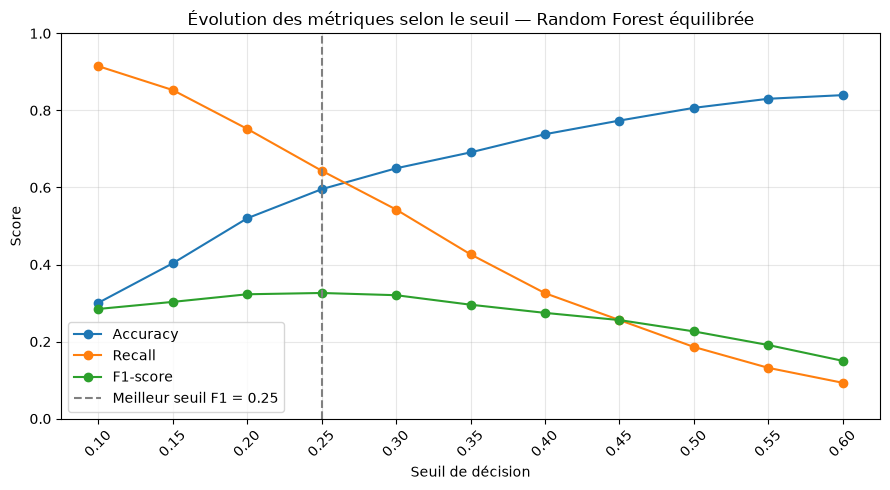

In [35]:
explorer_seuils_f(y_test_f, y_proba_rf_f, "Random Forest équilibrée")

Avec `class_weight="balanced"`, la Random Forest obtient au seuil par défaut un rappel de **16,3 %** et un F1-score de 0,208. En faisant varier le seuil, son meilleur F1-score atteint **0,326 au seuil de 0,25**, avec un rappel de 64,3 % et une accuracy de 59,6 %.

La pondération améliore donc la détection des patients positifs par rapport à la Random Forest initiale. Le résultat reste toutefois inférieur aux meilleurs scores obtenus avec les régressions logistiques.

### 4.5. Gradient Boosting


In [36]:
from sklearn.ensemble import GradientBoostingClassifier

# Création du modèle
modele_gb_f = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Entraînement
modele_gb_f.fit(X_train_f_prepared, y_train_f)

# Prédictions
y_pred_gb_f = modele_gb_f.predict(X_test_f_prepared)
y_proba_gb_f = modele_gb_f.predict_proba(X_test_f_prepared)[:, 1]

# Évaluation
print("Accuracy :", accuracy_score(y_test_f, y_pred_gb_f))
print("Precision :", precision_score(y_test_f, y_pred_gb_f))
print("Recall :", recall_score(y_test_f, y_pred_gb_f))
print("F1-score :", f1_score(y_test_f, y_pred_gb_f))
print("ROC-AUC :", roc_auc_score(y_test_f, y_proba_gb_f))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test_f, y_pred_gb_f))

print("\nRapport de classification :")
print(classification_report(y_test_f, y_pred_gb_f))

Accuracy : 0.8408018867924528
Precision : 0.36363636363636365
Recall : 0.06201550387596899
F1-score : 0.10596026490066225
ROC-AUC : 0.6646828605621503

Matrice de confusion :
[[705  14]
 [121   8]]

Rapport de classification :
              precision    recall  f1-score   support

           0       0.85      0.98      0.91       719
           1       0.36      0.06      0.11       129

    accuracy                           0.84       848
   macro avg       0.61      0.52      0.51       848
weighted avg       0.78      0.84      0.79       848



,Seuil,Accuracy,Precision,Recall,F1-score
0,0.10,0.527,0.207,0.744,0.324
1,0.15,0.662,0.233,0.535,0.325
2,0.20,0.739,0.250,0.357,0.294
3,0.25,0.779,0.273,0.271,0.272
4,0.30,0.808,0.302,0.202,0.242
5,0.35,0.817,0.283,0.132,0.180
6,0.40,0.831,0.341,0.116,0.173
7,0.45,0.842,0.414,0.093,0.152
8,0.50,0.841,0.364,0.062,0.106
9,0.55,0.844,0.400,0.047,0.083


Meilleur F1-score : 0.325 pour le seuil 0.15


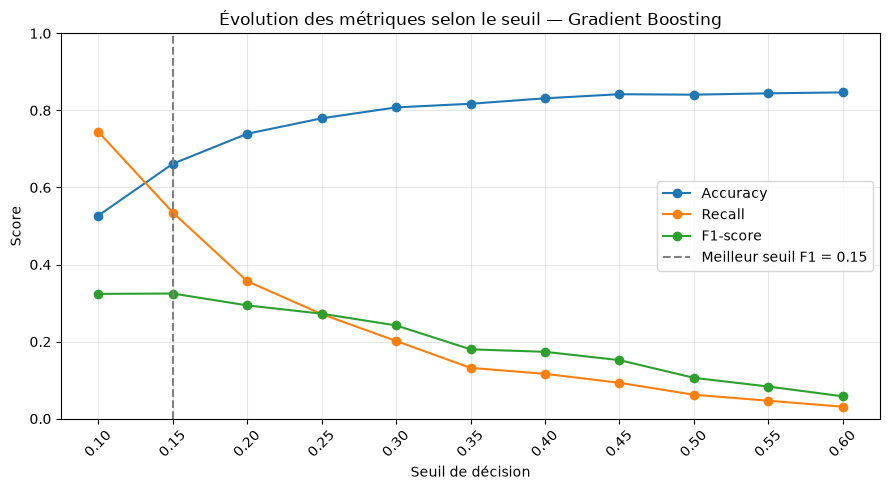

In [37]:
explorer_seuils_f(y_test_f, y_proba_gb_f, "Gradient Boosting")

In [38]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.ensemble import GradientBoostingClassifier

# Modèle de base
modele_gb_f = GradientBoostingClassifier(random_state=42)

# Grille des hyperparamètres à tester
parametres_gb_f = {
    "n_estimators": [100, 200],
    "learning_rate": [0.01, 0.1],
    "max_depth": [2, 3, 4],
    "min_samples_leaf": [5, 10],
    "subsample": [0.8, 1.0]
}

# Validation croisée stratifiée
cv_f = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Recherche des meilleurs paramètres
recherche_gb_f = GridSearchCV(
    estimator=modele_gb_f,
    param_grid=parametres_gb_f,
    scoring="f1",
    cv=cv_f,
    n_jobs=-1,
    verbose=1
)

# Entraînement et recherche
recherche_gb_f.fit(X_train_f_prepared, y_train_f)

# Meilleur modèle
meilleur_gb_f = recherche_gb_f.best_estimator_

print("Meilleurs paramètres :", recherche_gb_f.best_params_)
print("Meilleur F1-score en validation croisée :", recherche_gb_f.best_score_)

# Prédictions sur le jeu de test
y_pred_gb_opt_f = meilleur_gb_f.predict(X_test_f_prepared)
y_proba_gb_opt_f = meilleur_gb_f.predict_proba(X_test_f_prepared)[:, 1]

# Évaluation
print("\nAccuracy :", accuracy_score(y_test_f, y_pred_gb_opt_f))
print("Precision :", precision_score(y_test_f, y_pred_gb_opt_f))
print("Recall :", recall_score(y_test_f, y_pred_gb_opt_f))
print("F1-score :", f1_score(y_test_f, y_pred_gb_opt_f))
print("ROC-AUC :", roc_auc_score(y_test_f, y_proba_gb_opt_f))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test_f, y_pred_gb_opt_f))

print("\nRapport de classification :")
print(classification_report(y_test_f, y_pred_gb_opt_f))

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Meilleurs paramètres : {'learning_rate': 0.1, 'max_depth': 4, 'min_samples_leaf': 10, 'n_estimators': 200, 'subsample': 0.8}
Meilleur F1-score en validation croisée : 0.2161381076612865

Accuracy : 0.8242924528301887
Precision : 0.25
Recall : 0.07751937984496124
F1-score : 0.11834319526627218
ROC-AUC : 0.6229905877025586

Matrice de confusion :
[[689  30]
 [119  10]]

Rapport de classification :
              precision    recall  f1-score   support

           0       0.85      0.96      0.90       719
           1       0.25      0.08      0.12       129

    accuracy                           0.82       848
   macro avg       0.55      0.52      0.51       848
weighted avg       0.76      0.82      0.78       848



,Seuil,Accuracy,Precision,Recall,F1-score
0,0.10,0.587,0.210,0.620,0.314
1,0.15,0.678,0.223,0.450,0.298
2,0.20,0.738,0.246,0.349,0.288
3,0.25,0.761,0.236,0.256,0.245
4,0.30,0.782,0.254,0.225,0.239
5,0.35,0.792,0.236,0.163,0.193
6,0.40,0.804,0.232,0.124,0.162
7,0.45,0.812,0.232,0.101,0.141
8,0.50,0.824,0.250,0.078,0.118
9,0.55,0.829,0.233,0.054,0.088


Meilleur F1-score : 0.314 pour le seuil 0.10


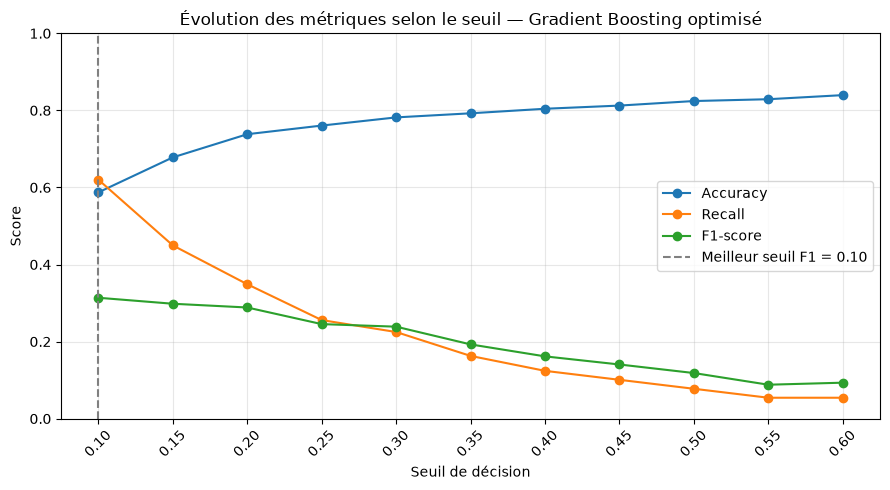

In [39]:
explorer_seuils_f(y_test_f, y_proba_gb_opt_f, "Gradient Boosting optimisé")

Au seuil par défaut, le Gradient Boosting obtient une accuracy de **84,1 %**, mais son rappel est faible (**6,2 %**) et son F1-score vaut 0,106. L'exploration des seuils donne un meilleur F1-score de **0,325 au seuil de 0,15**.

Pour le Gradient Boosting optimisé par `GridSearchCV`, le meilleur F1-score observé est de **0,314 au seuil de 0,10**. Dans cette expérience, l'optimisation des hyperparamètres n'améliore donc pas le meilleur F1-score obtenu après ajustement du seuil.

### 4.6. XGBoost


In [40]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

# Calcul du poids de la classe minoritaire
poids_classes_f = (y_train_f == 0).sum() / (y_train_f == 1).sum()

# Modèle de base
modele_xgb_opt_f = XGBClassifier(
    scale_pos_weight=poids_classes_f,
    eval_metric="logloss",
    random_state=42,
    n_jobs=1
)

# Grille des hyperparamètres
parametres_xgb_f = {
    "n_estimators": [200, 300, 500],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [2, 3, 4],
    "min_child_weight": [1, 3, 5],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}

# Validation croisée stratifiée
cv_xgb_f = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Recherche des meilleurs paramètres
recherche_xgb_f = GridSearchCV(
    estimator=modele_xgb_opt_f,
    param_grid=parametres_xgb_f,
    scoring="f1",
    cv=cv_xgb_f,
    n_jobs=-1,
    verbose=1
)

# Entraînement et recherche
recherche_xgb_f.fit(X_train_f_prepared, y_train_f)

# Meilleur modèle
meilleur_xgb_f = recherche_xgb_f.best_estimator_

print("Meilleurs paramètres :", recherche_xgb_f.best_params_)
print("Meilleur F1-score en validation croisée :",
      recherche_xgb_f.best_score_)

# Prédictions sur le jeu de test
y_pred_xgb_opt_f = meilleur_xgb_f.predict(X_test_f_prepared)
y_proba_xgb_opt_f = meilleur_xgb_f.predict_proba(X_test_f_prepared)[:, 1]

# Évaluation
print("\nAccuracy :", accuracy_score(y_test_f, y_pred_xgb_opt_f))
print("Precision :", precision_score(y_test_f, y_pred_xgb_opt_f))
print("Recall :", recall_score(y_test_f, y_pred_xgb_opt_f))
print("F1-score :", f1_score(y_test_f, y_pred_xgb_opt_f))
print("ROC-AUC :", roc_auc_score(y_test_f, y_proba_xgb_opt_f))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test_f, y_pred_xgb_opt_f))

print("\nRapport de classification :")
print(classification_report(y_test_f, y_pred_xgb_opt_f))

Fitting 5 folds for each of 324 candidates, totalling 1620 fits
Meilleurs paramètres : {'colsample_bytree': 1.0, 'learning_rate': 0.05, 'max_depth': 2, 'min_child_weight': 5, 'n_estimators': 300, 'subsample': 1.0}
Meilleur F1-score en validation croisée : 0.3811057338332886

Accuracy : 0.6568396226415094
Precision : 0.23355263157894737
Recall : 0.5503875968992248
F1-score : 0.3279445727482679
ROC-AUC : 0.6727905898588694

Matrice de confusion :
[[486 233]
 [ 58  71]]

Rapport de classification :
              precision    recall  f1-score   support

           0       0.89      0.68      0.77       719
           1       0.23      0.55      0.33       129

    accuracy                           0.66       848
   macro avg       0.56      0.61      0.55       848
weighted avg       0.79      0.66      0.70       848



,Seuil,Accuracy,Precision,Recall,F1-score
0,0.10,0.197,0.158,0.984,0.272
1,0.15,0.246,0.164,0.961,0.280
2,0.20,0.302,0.171,0.930,0.288
3,0.25,0.367,0.183,0.915,0.305
4,0.30,0.428,0.191,0.853,0.312
5,0.35,0.495,0.204,0.798,0.325
6,0.40,0.558,0.217,0.729,0.334
7,0.45,0.611,0.228,0.651,0.337
8,0.50,0.657,0.234,0.550,0.328
9,0.55,0.708,0.251,0.465,0.326


Meilleur F1-score : 0.337 pour le seuil 0.45


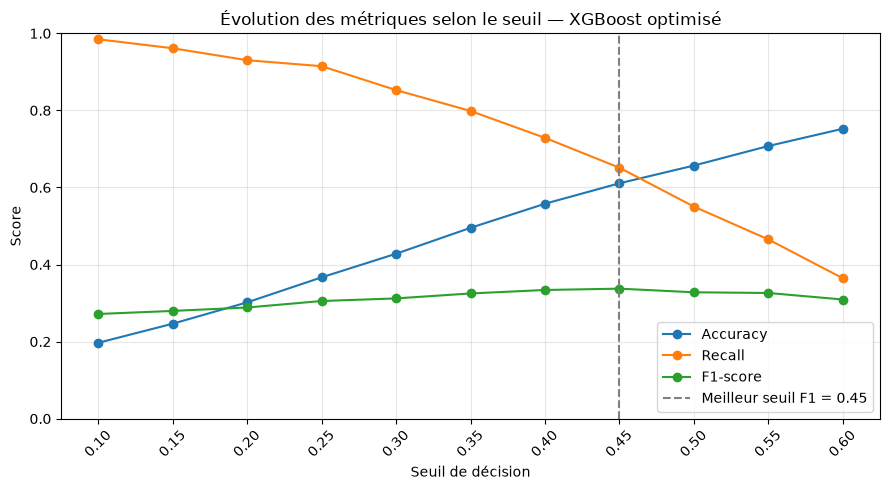

In [41]:
explorer_seuils_f(y_test_f, y_proba_xgb_opt_f, "XGBoost optimisé")

L'optimisation des hyperparamètres de XGBoost à l'aide de `GridSearchCV` donne un F1-score de **0,328 au seuil par défaut**. L'exploration des seuils permet d'atteindre un meilleur F1-score de **0,337 au seuil de 0,45**, avec une accuracy de 61,1 % et un rappel de 65,1 %.

Ce résultat est supérieur à celui de plusieurs modèles testés, mais reste inférieur à ceux des régressions logistiques avec seuil ajusté.

### 4.7. LightGBM


In [42]:
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

# Calcul du poids des classes
poids_classes_f = (y_train_f == 0).sum() / (y_train_f == 1).sum()

# Création du modèle
modele_lgbm_f = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    num_leaves=15,
    class_weight="balanced",
    random_state=42,
    verbosity=-1,
    n_jobs=-1
)

# Entraînement
modele_lgbm_f.fit(X_train_f_prepared, y_train_f)

# Prédictions
y_pred_lgbm_f = modele_lgbm_f.predict(X_test_f_prepared)
y_proba_lgbm_f = modele_lgbm_f.predict_proba(X_test_f_prepared)[:, 1]

# Évaluation
print("Accuracy :", accuracy_score(y_test_f, y_pred_lgbm_f))
print("Precision :", precision_score(y_test_f, y_pred_lgbm_f))
print("Recall :", recall_score(y_test_f, y_pred_lgbm_f))
print("F1-score :", f1_score(y_test_f, y_pred_lgbm_f))
print("ROC-AUC :", roc_auc_score(y_test_f, y_proba_lgbm_f))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test_f, y_pred_lgbm_f))

print("\nRapport de classification :")
print(classification_report(y_test_f, y_pred_lgbm_f))

Accuracy : 0.6957547169811321
Precision : 0.2301255230125523
Recall : 0.4263565891472868
F1-score : 0.29891304347826086
ROC-AUC : 0.633588856184839

Matrice de confusion :
[[535 184]
 [ 74  55]]

Rapport de classification :
              precision    recall  f1-score   support

           0       0.88      0.74      0.81       719
           1       0.23      0.43      0.30       129

    accuracy                           0.70       848
   macro avg       0.55      0.59      0.55       848
weighted avg       0.78      0.70      0.73       848



,Seuil,Accuracy,Precision,Recall,F1-score
0,0.10,0.271,0.163,0.915,0.276
1,0.15,0.342,0.175,0.899,0.294
2,0.20,0.395,0.183,0.860,0.302
3,0.25,0.455,0.192,0.806,0.310
4,0.30,0.499,0.188,0.690,0.295
5,0.35,0.561,0.201,0.636,0.306
6,0.40,0.620,0.222,0.597,0.324
7,0.45,0.656,0.220,0.496,0.305
8,0.50,0.696,0.230,0.426,0.299
9,0.55,0.722,0.228,0.349,0.276


Meilleur F1-score : 0.324 pour le seuil 0.40


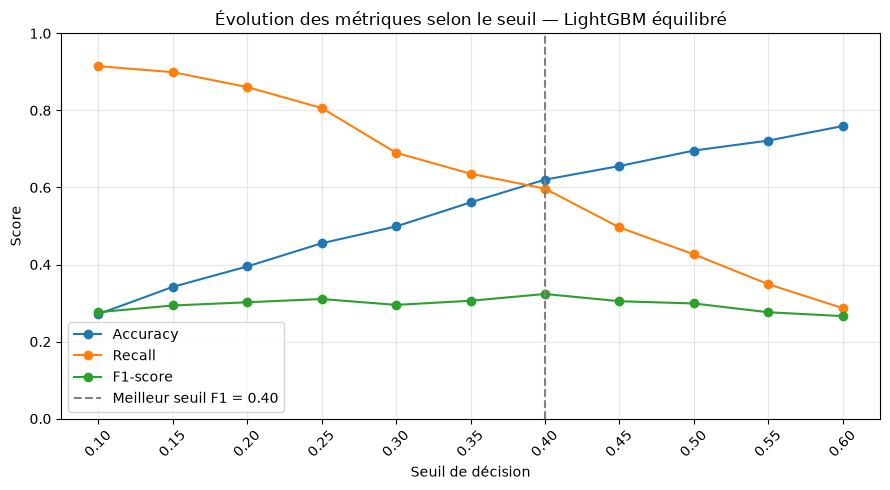

In [43]:
explorer_seuils_f(y_test_f, y_proba_lgbm_f, "LightGBM équilibré")

Au seuil par défaut, LightGBM obtient un F1-score de **0,299** et un rappel de 42,6 % (55 des 129 patients positifs détectés). L'exploration des seuils améliore son meilleur F1-score à **0,324 au seuil de 0,40**, avec un rappel de 59,7 %.

Ce résultat est supérieur à celui de plusieurs modèles testés, mais reste inférieur aux meilleurs résultats des régressions logistiques.

## 5. Prise en compte du déséquilibre des classes

Nous comparons maintenant différentes stratégies pour limiter l'effet du déséquilibre entre les classes. Les méthodes de rééchantillonnage sont appliquées uniquement aux données d'entraînement.

### 5.1. SMOTE

SMOTE (*Synthetic Minority Over-sampling Technique*) crée des observations synthétiques de la classe minoritaire à partir des observations existantes. L'objectif est d'équilibrer les effectifs des classes sans dupliquer simplement les mêmes individus.


In [44]:
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression


# 1. Rééquilibrage du jeu d'entraînement uniquement
smote_f = SMOTE(random_state=42)

X_train_smote_f, y_train_smote_f = smote_f.fit_resample(
    X_train_f_prepared, y_train_f
)

print("Répartition avant SMOTE :")
print(y_train_f.value_counts())

print("\nRépartition après SMOTE :")
print(y_train_smote_f.value_counts())

# 2. Création de la régression logistique
# Pas de class_weight="balanced", car SMOTE équilibre déjà les classes
modele_log_smote_f = LogisticRegression(
    random_state=42,
    max_iter=1000
)

# 3. Entraînement
modele_log_smote_f.fit(X_train_smote_f, y_train_smote_f)

# 4. Prédictions sur le jeu de test original
y_pred_log_smote_f = modele_log_smote_f.predict(X_test_f_prepared)
y_proba_log_smote_f = modele_log_smote_f.predict_proba(
    X_test_f_prepared
)[:, 1]

# 5. Évaluation
print("\nAccuracy :", accuracy_score(y_test_f, y_pred_log_smote_f))
print("Precision :", precision_score(y_test_f, y_pred_log_smote_f))
print("Recall :", recall_score(y_test_f, y_pred_log_smote_f))
print("F1-score :", f1_score(y_test_f, y_pred_log_smote_f))
print("ROC-AUC :", roc_auc_score(y_test_f, y_proba_log_smote_f))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test_f, y_pred_log_smote_f))

print("\nRapport de classification :")
print(classification_report(y_test_f, y_pred_log_smote_f))

Répartition avant SMOTE :
TenYearCHD
0    2877
1     515
Name: count, dtype: int64

Répartition après SMOTE :
TenYearCHD
0    2877
1    2877
Name: count, dtype: int64

Accuracy : 0.6568396226415094
Precision : 0.24367088607594936
Recall : 0.5968992248062015
F1-score : 0.34606741573033706
ROC-AUC : 0.6978145788185572

Matrice de confusion :
[[480 239]
 [ 52  77]]

Rapport de classification :
              precision    recall  f1-score   support

           0       0.90      0.67      0.77       719
           1       0.24      0.60      0.35       129

    accuracy                           0.66       848
   macro avg       0.57      0.63      0.56       848
weighted avg       0.80      0.66      0.70       848



,Seuil,Accuracy,Precision,Recall,F1-score
0,0.10,0.171,0.154,0.992,0.267
1,0.15,0.226,0.163,0.992,0.281
2,0.20,0.290,0.169,0.938,0.287
3,0.25,0.362,0.182,0.915,0.304
4,0.30,0.447,0.201,0.884,0.327
5,0.35,0.521,0.218,0.829,0.345
6,0.40,0.560,0.221,0.752,0.342
7,0.45,0.613,0.233,0.674,0.347
8,0.50,0.657,0.244,0.597,0.346
9,0.55,0.711,0.272,0.535,0.360


Meilleur F1-score : 0.360 pour le seuil 0.55


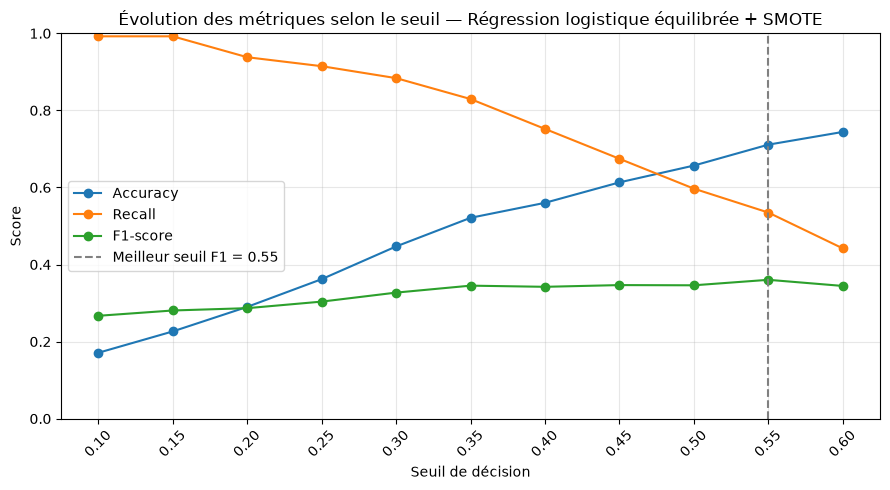

In [45]:
explorer_seuils_f(y_test_f, y_proba_log_smote_f, "Régression logistique équilibrée + SMOTE")

Au seuil par défaut, la régression logistique entraînée après application de SMOTE obtient un F1-score de **0,346**, avec une précision de 24,4 % et un rappel de 59,7 %.

En explorant les différents seuils, le meilleur F1-score atteint **0,360 au seuil de 0,55**. Ce résultat est légèrement supérieur à celui de la régression logistique équilibrée (0,359).

### 5.2. Random Undersampling

Le *Random Undersampling* réduit le nombre d'observations de la classe majoritaire afin d'équilibrer les effectifs. Contrairement à SMOTE, cette méthode ne crée pas de nouvelles observations : elle retire une partie des observations de la classe majoritaire, ce qui entraîne une perte d'information potentielle.


In [46]:
from imblearn.under_sampling import RandomUnderSampler
from sklearn.linear_model import LogisticRegression


# 1. Sous-échantillonnage de la classe majoritaire
rus_f = RandomUnderSampler(random_state=42)

X_train_under_f, y_train_under_f = rus_f.fit_resample(
    X_train_f_prepared, y_train_f
)

# Répartition des classes après sous-échantillonnage
print("Répartition avant sous-échantillonnage :")
print(y_train_f.value_counts())

print("\nRépartition après sous-échantillonnage :")
print(y_train_under_f.value_counts())


# 2. Entraînement de la régression logistique
modele_log_under_f = LogisticRegression(
    random_state=42,
    max_iter=1000
)

modele_log_under_f.fit(X_train_under_f, y_train_under_f)


# 3. Prédictions sur le jeu de test
y_pred_log_under_f = modele_log_under_f.predict(X_test_f_prepared)

y_proba_log_under_f = modele_log_under_f.predict_proba(
    X_test_f_prepared
)[:, 1]


# 4. Évaluation du modèle
print("\n--- Résultats du modèle ---")

print("Accuracy :", accuracy_score(y_test_f, y_pred_log_under_f))
print("Precision :", precision_score(y_test_f, y_pred_log_under_f))
print("Recall :", recall_score(y_test_f, y_pred_log_under_f))
print("F1-score :", f1_score(y_test_f, y_pred_log_under_f))
print("ROC-AUC :", roc_auc_score(y_test_f, y_proba_log_under_f))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test_f, y_pred_log_under_f))

print("\nRapport de classification :")
print(classification_report(y_test_f, y_pred_log_under_f))

Répartition avant sous-échantillonnage :
TenYearCHD
0    2877
1     515
Name: count, dtype: int64

Répartition après sous-échantillonnage :
TenYearCHD
0    515
1    515
Name: count, dtype: int64

--- Résultats du modèle ---
Accuracy : 0.6615566037735849
Precision : 0.2484076433121019
Recall : 0.6046511627906976
F1-score : 0.35214446952595935
ROC-AUC : 0.6956906125001348

Matrice de confusion :
[[483 236]
 [ 51  78]]

Rapport de classification :
              precision    recall  f1-score   support

           0       0.90      0.67      0.77       719
           1       0.25      0.60      0.35       129

    accuracy                           0.66       848
   macro avg       0.58      0.64      0.56       848
weighted avg       0.80      0.66      0.71       848



,Seuil,Accuracy,Precision,Recall,F1-score
0,0.10,0.165,0.154,1.000,0.267
1,0.15,0.209,0.160,0.992,0.276
2,0.20,0.267,0.166,0.953,0.283
3,0.25,0.333,0.175,0.915,0.294
4,0.30,0.407,0.190,0.891,0.314
5,0.35,0.498,0.215,0.868,0.345
6,0.40,0.551,0.220,0.767,0.342
7,0.45,0.601,0.231,0.698,0.347
8,0.50,0.662,0.248,0.605,0.352
9,0.55,0.723,0.288,0.558,0.380


Meilleur F1-score : 0.380 pour le seuil 0.55


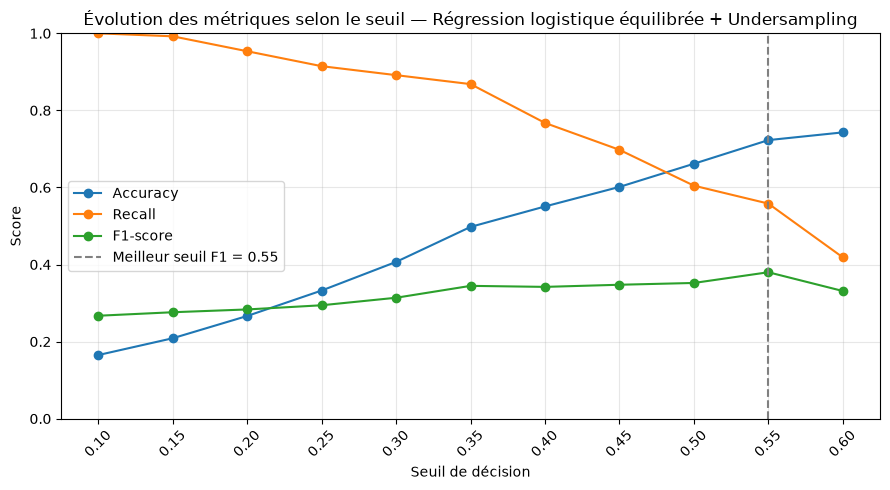

In [47]:
explorer_seuils_f(y_test_f, y_proba_log_under_f, "Régression logistique équilibrée + Undersampling")

Au seuil par défaut, les trois stratégies donnent des F1-scores proches : **0,359** pour la régression logistique équilibrée, **0,346** pour SMOTE et **0,352** pour le Random Undersampling.

Après exploration des seuils, le Random Undersampling obtient le meilleur F1-score (**0,380 au seuil de 0,55**), devant la régression logistique sans pondération (**0,364 au seuil de 0,15**), SMOTE (**0,360 au seuil de 0,55**) et la régression logistique équilibrée (**0,359 au seuil de 0,55**).

Ces résultats sont exploratoires, car les seuils ont été comparés sur le jeu de test. Ils permettent de repérer le Random Undersampling comme meilleure candidate selon le F1-score, mais le seuil définitif doit être choisi sur le jeu de validation. Le jeu de test ayant déjà été utilisé pour ces comparaisons, les performances finales doivent être interprétées avec prudence.


### 5.3. Comparaison des modèles selon le seuil de décision

Le seuil de décision par défaut est fixé à 0,5. Cependant, dans un problème de classification déséquilibré, modifier ce seuil peut améliorer le rappel ou le F1-score.

Nous testons donc les mêmes seuils pour tous les modèles afin de comparer leur comportement. Pour chaque seuil, nous calculons l'accuracy, le rappel et le F1-score.

**Attention :** cette comparaison est exploratoire et repose sur le jeu de test déjà utilisé précédemment. Elle permet d'étudier les compromis entre les métriques, mais ne doit pas être utilisée seule pour sélectionner le modèle final ou son seuil.


Meilleur seuil et meilleur F1-score pour chaque modèle :


,Modèle,Seuil,Accuracy,Recall,F1-score
0,Régression logistique + undersampling,0.55,0.723,0.558,0.380
1,Régression logistique,0.15,0.670,0.620,0.364
2,Régression logistique + SMOTE,0.55,0.711,0.535,0.360
3,Régression logistique équilibrée,0.55,0.718,0.519,0.359
4,XGBoost optimisé,0.45,0.611,0.651,0.337
5,Random Forest équilibrée,0.25,0.596,0.643,0.326
6,Gradient Boosting,0.15,0.662,0.535,0.325
7,LightGBM équilibré,0.40,0.620,0.597,0.324
8,Random Forest,0.10,0.486,0.775,0.314
9,Gradient Boosting optimisé,0.10,0.587,0.620,0.314


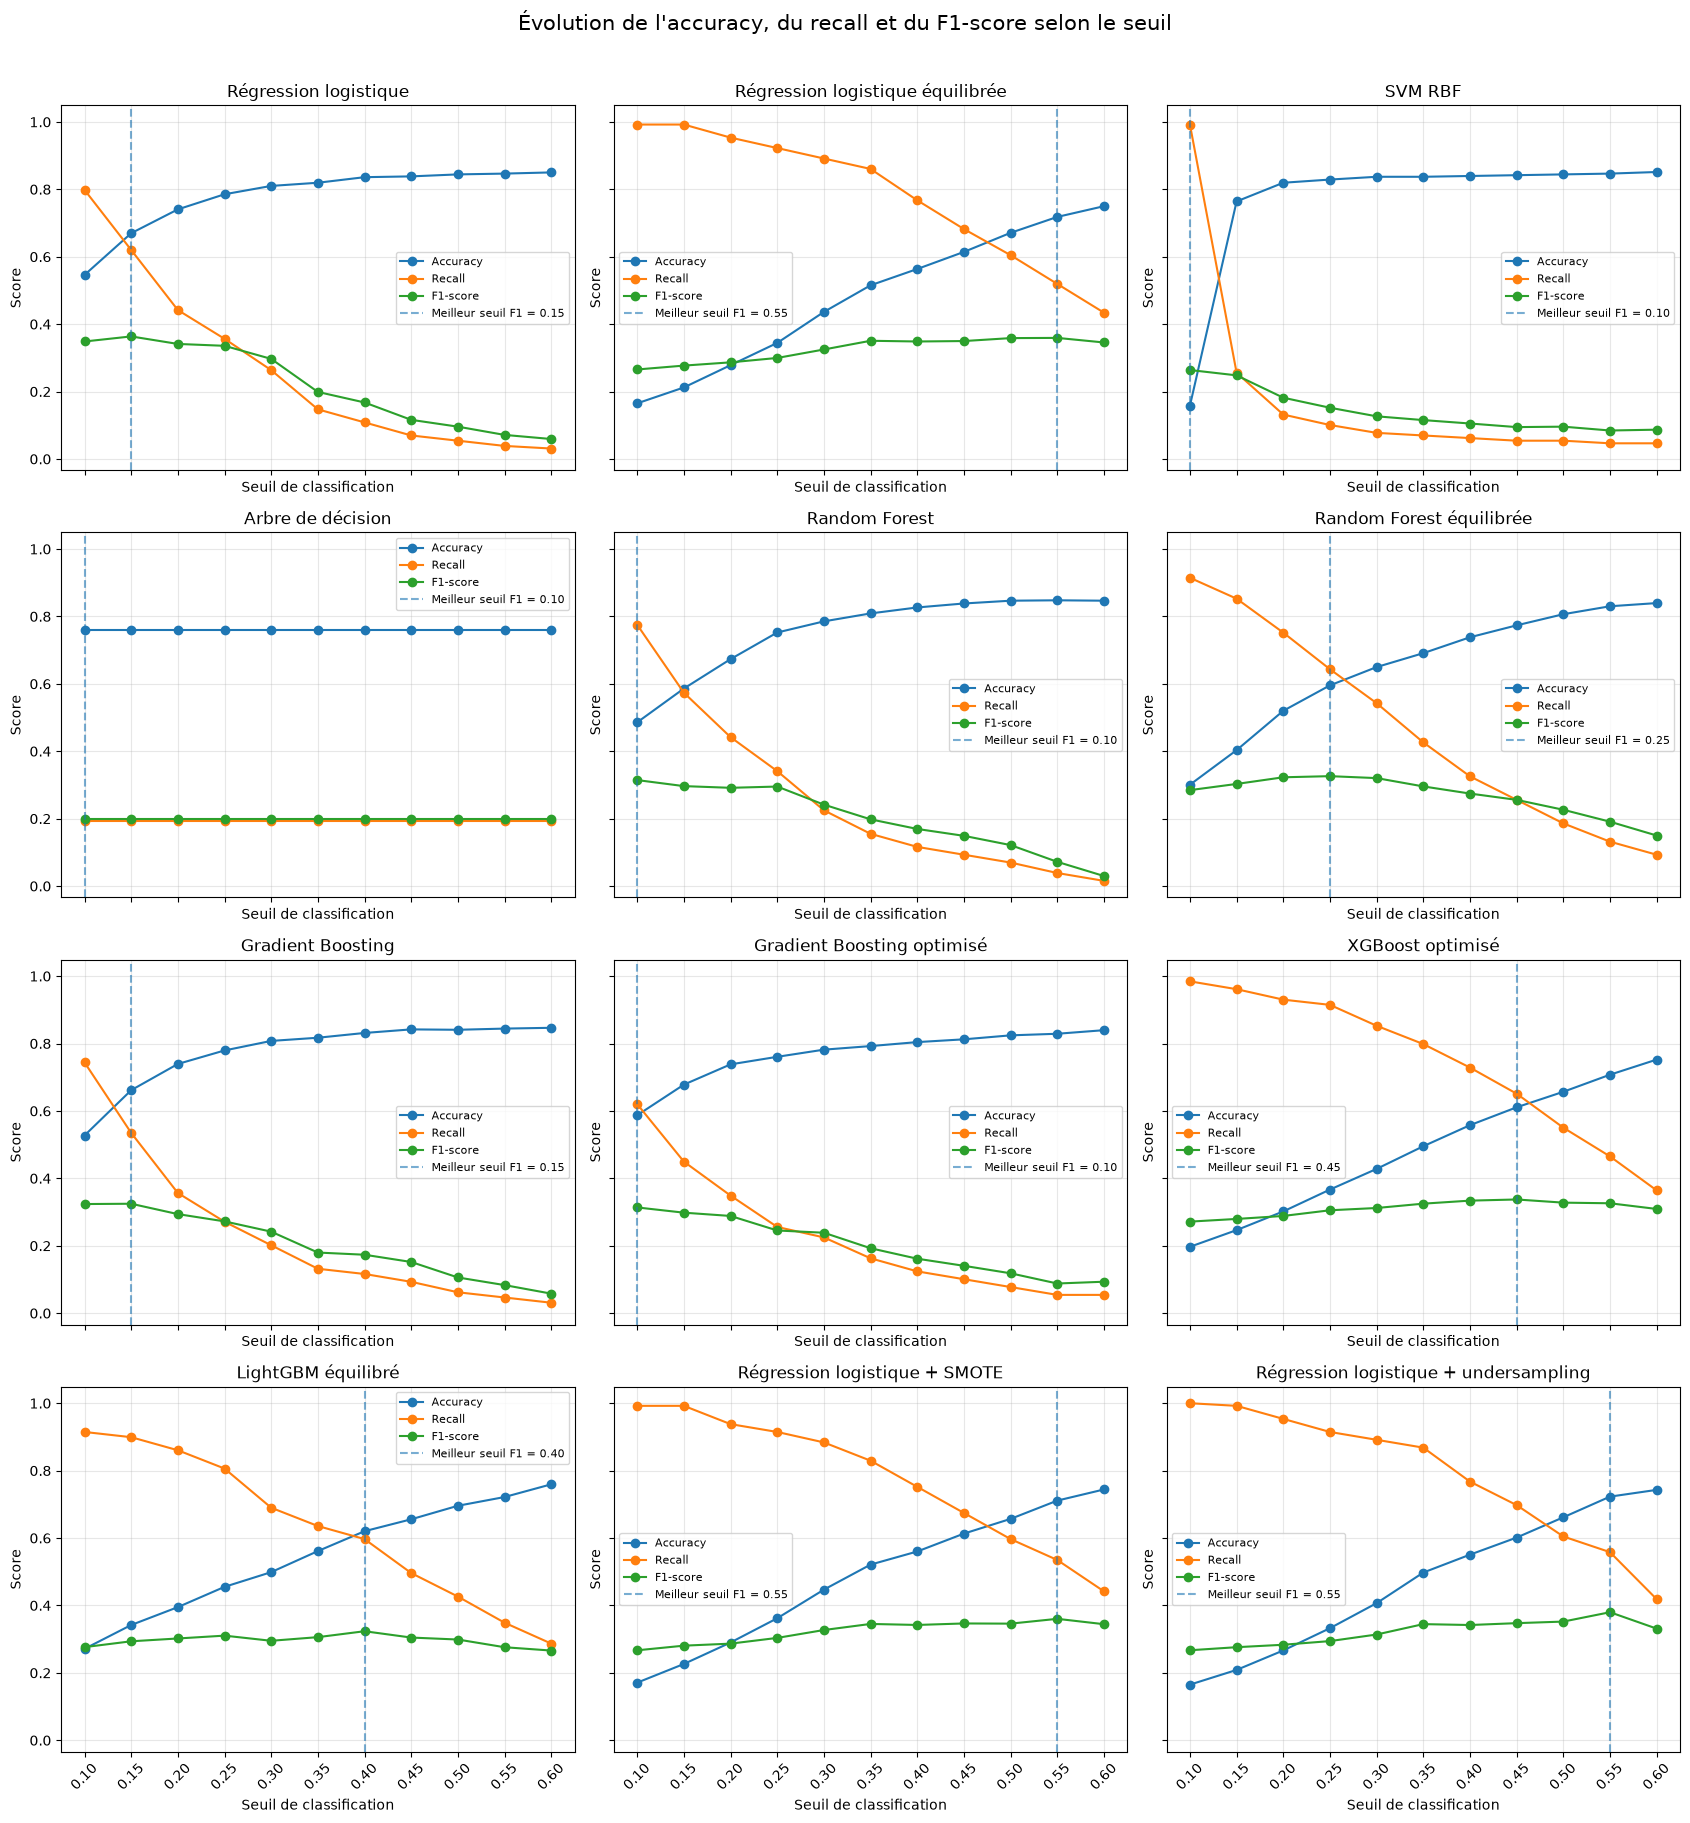

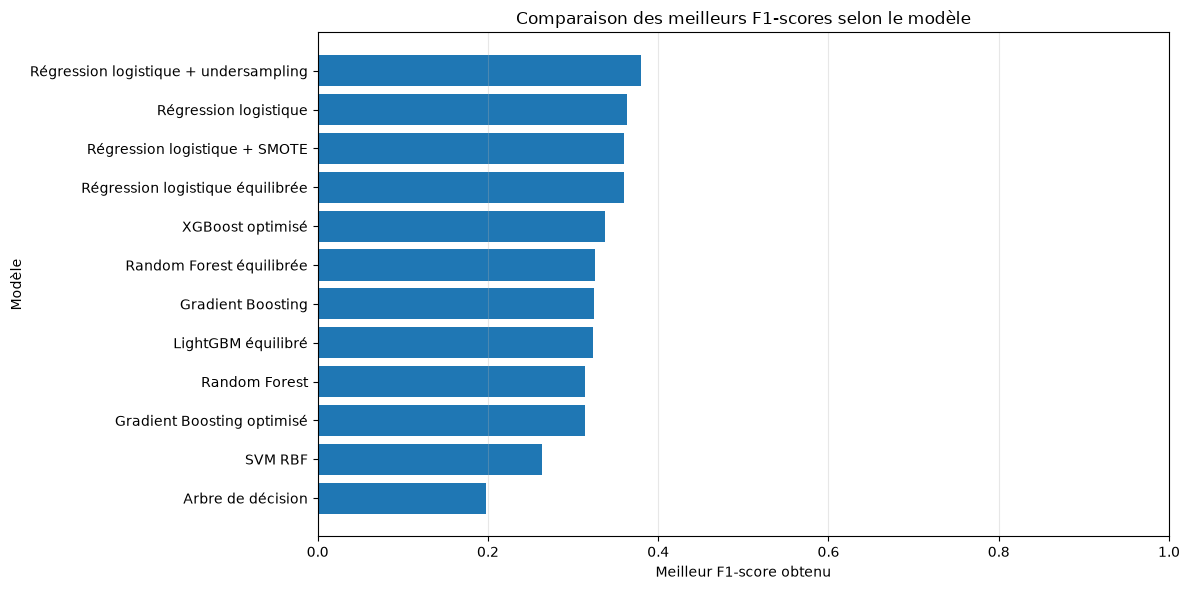

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    recall_score,
    f1_score
)

# Seuils communs à tous les modèles
seuils_f = [
    0.10, 0.15, 0.20, 0.25, 0.30, 0.35,
    0.40, 0.45, 0.50, 0.55, 0.60
]

# Probabilités prédites pour la classe positive par chaque modèle
# Les modèles doivent avoir été entraînés dans les cellules précédentes.
probabilites_modeles_f = {
    "Régression logistique": y_proba_log_f,
    "Régression logistique équilibrée": y_proba_log_bal_f,
    "SVM RBF": y_proba_svm_f,
    "Arbre de décision": y_proba_arbre_f,
    "Random Forest": y_proba_rf_initial_f,
    "Random Forest équilibrée": y_proba_rf_bal_f,
    "Gradient Boosting": y_proba_gb_f,
    "Gradient Boosting optimisé": y_proba_gb_opt_f,
    "XGBoost optimisé": y_proba_xgb_opt_f,
    "LightGBM équilibré": y_proba_lgbm_f,
    "Régression logistique + SMOTE": y_proba_log_smote_f,
    "Régression logistique + undersampling": y_proba_log_under_f
}

# Vérification des probabilités disponibles
probabilites_modeles_f = {
    nom: proba
    for nom, proba in probabilites_modeles_f.items()
    if proba is not None
}

resultats_tous_modeles_f = []

# Calcul des métriques pour chaque modèle et chaque seuil
for nom_modele, probabilites in probabilites_modeles_f.items():

    for seuil in seuils_f:

        predictions = (probabilites >= seuil).astype(int)

        resultats_tous_modeles_f.append({
            "Modèle": nom_modele,
            "Seuil": seuil,
            "Accuracy": accuracy_score(y_test_f, predictions),
            "Recall": recall_score(
                y_test_f, predictions, zero_division=0
            ),
            "F1-score": f1_score(
                y_test_f, predictions, zero_division=0
            )
        })

tableau_comparaison_seuils_f = pd.DataFrame(
    resultats_tous_modeles_f
)

# Tableau récapitulatif des meilleurs seuils selon le F1-score
indices_meilleurs_f1 = (
    tableau_comparaison_seuils_f
    .groupby("Modèle")["F1-score"]
    .idxmax()
)

meilleurs_resultats_f = (
    tableau_comparaison_seuils_f
    .loc[indices_meilleurs_f1]
    .sort_values("F1-score", ascending=False)
    .reset_index(drop=True)
)

print("Meilleur seuil et meilleur F1-score pour chaque modèle :")
display(
    meilleurs_resultats_f[
        ["Modèle", "Seuil", "Accuracy", "Recall", "F1-score"]
    ].round(3)
)

# Graphiques : accuracy, recall et F1-score selon le seuil,
# avec un sous-graphique par modèle.
n_modeles_f = len(probabilites_modeles_f)
n_colonnes_f = 3
n_lignes_f = int(np.ceil(n_modeles_f / n_colonnes_f))

fig, axes = plt.subplots(
    n_lignes_f,
    n_colonnes_f,
    figsize=(17, 4.5 * n_lignes_f),
    sharex=True,
    sharey=True
)

axes = np.array(axes).reshape(-1)

for ax, nom_modele in zip(axes, probabilites_modeles_f.keys()):

    donnees_modele = tableau_comparaison_seuils_f[
        tableau_comparaison_seuils_f["Modèle"] == nom_modele
    ]

    ax.plot(
        donnees_modele["Seuil"],
        donnees_modele["Accuracy"],
        marker="o",
        label="Accuracy"
    )

    ax.plot(
        donnees_modele["Seuil"],
        donnees_modele["Recall"],
        marker="o",
        label="Recall"
    )

    ax.plot(
        donnees_modele["Seuil"],
        donnees_modele["F1-score"],
        marker="o",
        label="F1-score"
    )

    meilleur = donnees_modele.loc[
        donnees_modele["F1-score"].idxmax()
    ]

    ax.axvline(
        meilleur["Seuil"],
        linestyle="--",
        alpha=0.6,
        label=f"Meilleur seuil F1 = {meilleur['Seuil']:.2f}"
    )

    ax.set_title(nom_modele)
    ax.set_xlabel("Seuil de classification")
    ax.set_ylabel("Score")
    ax.set_xticks(seuils_f)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

# Masquer les cases inutilisées
for ax in axes[n_modeles_f:]:
    ax.set_visible(False)

fig.suptitle(
    "Évolution de l'accuracy, du recall et du F1-score selon le seuil",
    fontsize=15,
    y=1.01
)
plt.tight_layout()
plt.show()

# Graphique comparatif des meilleurs F1-scores
plt.figure(figsize=(12, 6))

plt.barh(
    meilleurs_resultats_f["Modèle"],
    meilleurs_resultats_f["F1-score"]
)

plt.xlabel("Meilleur F1-score obtenu")
plt.ylabel("Modèle")
plt.title("Comparaison des meilleurs F1-scores selon le modèle")
plt.xlim(0, 1)
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

La comparaison des meilleurs F1-scores pour les douze modèles est présentée ci-dessous. Les seuils indiqués sont ceux qui maximisent le F1-score parmi les valeurs testées sur le jeu de test.

| Modèle | Meilleur seuil testé | Accuracy | Recall | F1-score |
|---|---:|---:|---:|---:|
| Régression logistique + Random Undersampling | 0,55 | 0,723 | 0,558 | **0,380** |
| Régression logistique | 0,15 | 0,670 | 0,620 | 0,364 |
| Régression logistique + SMOTE | 0,55 | 0,711 | 0,535 | 0,360 |
| Régression logistique équilibrée | 0,55 | 0,718 | 0,519 | 0,359 |
| XGBoost optimisé | 0,45 | 0,611 | 0,651 | 0,337 |
| Random Forest équilibrée | 0,25 | 0,596 | 0,643 | 0,326 |
| Gradient Boosting | 0,15 | 0,662 | 0,535 | 0,325 |
| LightGBM équilibré | 0,40 | 0,620 | 0,597 | 0,324 |
| Random Forest | 0,10 | 0,486 | 0,775 | 0,314 |
| Gradient Boosting optimisé | 0,10 | 0,587 | 0,620 | 0,314 |
| SVM RBF | 0,10 | 0,158 | 0,992 | 0,264 |
| Arbre de décision | 0,10 | 0,761 | 0,194 | 0,198 |

Le meilleur F1-score exploratoire est donc obtenu par la **régression logistique avec Random Undersampling** (0,380 au seuil de 0,55). Elle présente également une accuracy de 72,3 % et un rappel de 55,8 %. La régression logistique sans pondération arrive en deuxième position (F1-score de 0,364), suivie de SMOTE (0,360) et de la régression logistique équilibrée (0,359).

Nous retenons le Random Undersampling comme candidate à confirmer sur le jeu de validation ; le seuil final sera choisi sur ce dernier.

## 6. Sélection et entraînement du modèle final

La comparaison exploratoire des douze modèles place la **régression logistique avec Random Undersampling** en tête selon le F1-score (0,380 au seuil de 0,55). Nous retenons donc cette méthode comme candidate pour la procédure finale.

Le choix du seuil est réalisé exclusivement sur le jeu de validation. Le prétraitement et le sous-échantillonnage sont ajustés uniquement sur les données d'entraînement afin d'éviter toute fuite d'information. Le modèle est ensuite réentraîné sur l'ensemble des données d'entraînement et de validation, puis évalué sur le jeu de test avec le seuil fixé.

Il faut garder à l'esprit que le jeu de test a déjà été consulté lors des expérimentations exploratoires ; l'évaluation finale ne peut donc pas être considérée comme totalement indépendante.

In [49]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from imblearn.under_sampling import RandomUnderSampler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# --------------------------------------------------
# 1. Séparation du jeu d'entraînement en train/validation
# --------------------------------------------------

X_train_sub_f, X_val_f, y_train_sub_f, y_val_f = train_test_split(
    X_train_f,
    y_train_f,
    test_size=0.2,
    random_state=42,
    stratify=y_train_f
)

print("Taille entraînement :", X_train_sub_f.shape)
print("Taille validation :", X_val_f.shape)
print("Taille test :", X_test_f.shape)

# --------------------------------------------------
# 2. Prétraitement : ajustement uniquement sur le train
# --------------------------------------------------

pipeline_quant_f = Pipeline([
    ("imputation", SimpleImputer(strategy="median")),
    ("standardisation", StandardScaler())
])

pipeline_cat_f = Pipeline([
    ("imputation", SimpleImputer(strategy="most_frequent"))
])

process_final_f = ColumnTransformer([
    ("quantitatives", pipeline_quant_f, variables_quantitatives_f),
    ("categorielles", pipeline_cat_f, variables_categorielles_f)
])

X_train_sub_prepared_f = process_final_f.fit_transform(X_train_sub_f)
X_val_prepared_f = process_final_f.transform(X_val_f)

# --------------------------------------------------
# 3. Random Undersampling appliqué uniquement au train
# --------------------------------------------------

undersampler_final_f = RandomUnderSampler(random_state=42)

X_train_under_f, y_train_under_f = undersampler_final_f.fit_resample(
    X_train_sub_prepared_f,
    y_train_sub_f
)

print("\nRépartition après undersampling :")
print(pd.Series(y_train_under_f).value_counts())

# --------------------------------------------------
# 4. Entraînement de la régression logistique
# --------------------------------------------------

modele_final_f = LogisticRegression(
    random_state=42,
    max_iter=1000
)

modele_final_f.fit(X_train_under_f, y_train_under_f)

# --------------------------------------------------
# 5. Recherche du meilleur seuil sur la validation
# --------------------------------------------------

y_proba_val_f = modele_final_f.predict_proba(X_val_prepared_f)[:, 1]
seuils_f = np.arange(0.10, 0.81, 0.01)

resultats_validation_f = []

for seuil in seuils_f:
    y_pred_val_f = (y_proba_val_f >= seuil).astype(int)
    resultats_validation_f.append({
        "Seuil": seuil,
        "Precision": precision_score(y_val_f, y_pred_val_f, zero_division=0),
        "Recall": recall_score(y_val_f, y_pred_val_f, zero_division=0),
        "F1-score": f1_score(y_val_f, y_pred_val_f, zero_division=0)
    })

tableau_validation_f = pd.DataFrame(resultats_validation_f)
meilleur_indice_f = tableau_validation_f["F1-score"].idxmax()
meilleur_seuil_f = tableau_validation_f.loc[meilleur_indice_f, "Seuil"]

print("\nMeilleur seuil sur la validation :", round(meilleur_seuil_f, 2))
print(tableau_validation_f.loc[meilleur_indice_f])

# --------------------------------------------------
# 6. Évaluation sur le jeu de test avec le seuil fixé
# --------------------------------------------------

X_test_final_prepared_f = process_final_f.transform(X_test_f)
y_proba_test_f = modele_final_f.predict_proba(X_test_final_prepared_f)[:, 1]
y_pred_test_f = (y_proba_test_f >= meilleur_seuil_f).astype(int)

print("\n--- Résultats sur le jeu de test ---")
print("Seuil choisi :", round(meilleur_seuil_f, 2))
print("Accuracy :", accuracy_score(y_test_f, y_pred_test_f))
print("Precision :", precision_score(y_test_f, y_pred_test_f, zero_division=0))
print("Recall :", recall_score(y_test_f, y_pred_test_f, zero_division=0))
print("F1-score :", f1_score(y_test_f, y_pred_test_f, zero_division=0))
print("ROC-AUC :", roc_auc_score(y_test_f, y_proba_test_f))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test_f, y_pred_test_f))

print("\nRapport de classification :")
print(classification_report(y_test_f, y_pred_test_f))

Taille entraînement : (2713, 15)
Taille validation : (679, 15)
Taille test : (848, 15)

Répartition après undersampling :
TenYearCHD
0    412
1    412
Name: count, dtype: int64

Meilleur seuil sur la validation : 0.52
Seuil        0.520000
Precision    0.257778
Recall       0.563107
F1-score     0.353659
Name: 42, dtype: float64

--- Résultats sur le jeu de test ---
Seuil choisi : 0.52
Accuracy : 0.6981132075471698
Precision : 0.26394052044609667
Recall : 0.5503875968992248
F1-score : 0.35678391959798994
ROC-AUC : 0.6908496943429181

Matrice de confusion :
[[521 198]
 [ 58  71]]

Rapport de classification :
              precision    recall  f1-score   support

           0       0.90      0.72      0.80       719
           1       0.26      0.55      0.36       129

    accuracy                           0.70       848
   macro avg       0.58      0.64      0.58       848
weighted avg       0.80      0.70      0.73       848



Le seuil qui maximise le F1-score sur le jeu de validation est déterminé à partir des probabilités prédites par la régression logistique entraînée après Random Undersampling. Il est ensuite conservé pour l'évaluation finale, sans réoptimisation sur le jeu de test.

Nous réentraînons le préprocesseur sur l'ensemble des données d'entraînement et de validation (80 % du jeu initial), puis nous appliquons le Random Undersampling uniquement à cet ensemble d'entraînement. Le jeu de test conserve ainsi sa distribution d'origine et sert à calculer les métriques du modèle réentraîné.

La performance finale devra être interprétée avec prudence : le jeu de test a déjà été consulté pendant la phase exploratoire. Une validation sur un jeu externe, indépendant, serait nécessaire pour évaluer plus rigoureusement la capacité de généralisation.

In [50]:
# ============================================================
# 1. Regrouper les données d'entraînement et de validation
# ============================================================

import pandas as pd
import numpy as np

X_train_complet_f = pd.concat([X_train_sub_f, X_val_f])
y_train_complet_f = pd.concat([y_train_sub_f, y_val_f])

print("Dimensions de l'ensemble d'entraînement :", X_train_complet_f.shape)

# ============================================================
# 2. Créer et ajuster le préprocesseur sur les 80 % d'entraînement
# ============================================================

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from imblearn.under_sampling import RandomUnderSampler

pipeline_quant_f = Pipeline([
    ("imputation", SimpleImputer(strategy="median")),
    ("standardisation", StandardScaler())
])

pipeline_cat_f = Pipeline([
    ("imputation", SimpleImputer(strategy="most_frequent"))
])

process_final_f = ColumnTransformer([
    ("quantitatives", pipeline_quant_f, variables_quantitatives_f),
    ("categorielles", pipeline_cat_f, variables_categorielles_f)
])

X_train_complet_prepared_f = process_final_f.fit_transform(X_train_complet_f)
X_test_final_prepared_f = process_final_f.transform(X_test_f)

# ============================================================
# 3. Appliquer le Random Undersampling uniquement à l'entraînement
# ============================================================

undersampler_final_f = RandomUnderSampler(random_state=42)

X_train_under_f, y_train_under_f = undersampler_final_f.fit_resample(
    X_train_complet_prepared_f,
    y_train_complet_f
)

print("\nRépartition après undersampling :")
print(pd.Series(y_train_under_f).value_counts())

# ============================================================
# 4. Entraîner le modèle final
# ============================================================

modele_final_f = LogisticRegression(
    random_state=42,
    max_iter=1000
)

modele_final_f.fit(X_train_under_f, y_train_under_f)

# ============================================================
# 5. Prédictions sur le jeu de test
# ============================================================

y_proba_final_f = modele_final_f.predict_proba(X_test_final_prepared_f)[:, 1]

# Le seuil a été choisi sur le jeu de validation dans la cellule précédente.
seuil_final_f = meilleur_seuil_f

y_pred_final_f = (y_proba_final_f >= seuil_final_f).astype(int)

# ============================================================
# 6. Évaluation du modèle final
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("\n===== PERFORMANCES DU MODÈLE FINAL =====")
print("Seuil final :", round(seuil_final_f, 2))
print("Accuracy :", accuracy_score(y_test_f, y_pred_final_f))
print("Precision :", precision_score(y_test_f, y_pred_final_f, zero_division=0))
print("Recall :", recall_score(y_test_f, y_pred_final_f, zero_division=0))
print("F1-score :", f1_score(y_test_f, y_pred_final_f, zero_division=0))
print("ROC-AUC :", roc_auc_score(y_test_f, y_proba_final_f))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test_f, y_pred_final_f))

print("\nRapport de classification :")
print(classification_report(y_test_f, y_pred_final_f))

Dimensions de l'ensemble d'entraînement : (3392, 15)

Répartition après undersampling :
TenYearCHD
0    515
1    515
Name: count, dtype: int64

===== PERFORMANCES DU MODÈLE FINAL =====
Seuil final : 0.52
Accuracy : 0.6922169811320755
Precision : 0.2692307692307692
Recall : 0.5968992248062015
F1-score : 0.3710843373493976
ROC-AUC : 0.694235102586495

Matrice de confusion :
[[510 209]
 [ 52  77]]

Rapport de classification :
              precision    recall  f1-score   support

           0       0.91      0.71      0.80       719
           1       0.27      0.60      0.37       129

    accuracy                           0.69       848
   macro avg       0.59      0.65      0.58       848
weighted avg       0.81      0.69      0.73       848



## 7. Conclusion

L'objectif de ce projet était de développer un modèle de machine learning capable de prédire la survenue d'une maladie coronarienne dans les dix années à venir, à partir de données cliniques et de facteurs de risque individuels.

L'analyse exploratoire du jeu de données de Framingham a mis en évidence un déséquilibre important entre les deux classes : environ **85 %** des patients ne développent pas de maladie coronarienne dans les dix ans, contre **15 %** qui en développent une. Ce déséquilibre constitue une difficulté pour la classification, car un modèle peut obtenir une accuracy élevée tout en détectant très peu de cas positifs.

L'analyse des relations avec la cible montre des différences statistiquement significatives pour sept des huit variables quantitatives étudiées, ainsi que des associations pour six des sept variables qualitatives. Ces associations restent toutefois généralement faibles et ne permettent pas, à elles seules, de prédire individuellement la survenue de la maladie.

Plusieurs algorithmes ont été étudiés : régression logistique, SVM, arbre de décision, Random Forest, Gradient Boosting, XGBoost et LightGBM. Nous avons également comparé différentes stratégies de prise en compte du déséquilibre des classes : pondération des classes, SMOTE et Random Undersampling. L'exploration de plusieurs seuils de décision sur le jeu de test donne le meilleur F1-score à la **régression logistique avec Random Undersampling : 0,380 au seuil de 0,55**. Elle est suivie par la régression logistique sans pondération (0,364 au seuil de 0,15), SMOTE (0,360 au seuil de 0,55) et la régression logistique équilibrée (0,359 au seuil de 0,55).

Cette comparaison reste exploratoire, car les seuils ont été évalués sur le jeu de test. Nous avons donc retenu la régression logistique avec Random Undersampling comme candidate, puis adapté la procédure finale : le sous-échantillonnage est appliqué uniquement aux données d'entraînement, le seuil est sélectionné sur le jeu de validation, et le modèle est réentraîné sur l'ensemble entraînement-validation avant son évaluation sur le jeu de test. **Les métriques finales devront être actualisées après réexécution des cellules de sélection et d'entraînement final**, car les anciennes sorties correspondaient à une régression logistique équilibrée et ne sont plus valables pour cette nouvelle procédure.

Les résultats obtenus jusqu'ici montrent qu'il est nécessaire de considérer plusieurs métriques. Une accuracy élevée ne suffit pas à caractériser un modèle, particulièrement lorsque la classe positive est minoritaire : le rappel, la précision et le F1-score permettent aussi d'évaluer sa capacité à identifier les patients à risque et le coût en faux positifs.

Le modèle développé reste une approche exploratoire. Il ne peut pas être considéré comme un outil de diagnostic ou d'aide à la décision médicale. Une validation sur un jeu de données externe, totalement indépendant des expérimentations, serait nécessaire pour évaluer plus rigoureusement sa capacité de généralisation.

Plusieurs pistes pourraient être envisagées pour améliorer les résultats : enrichir le jeu de données avec davantage d'individus et de variables cliniques, étudier d'autres méthodes de sélection de variables et d'optimisation des hyperparamètres, ou explorer des modèles capables de mieux représenter les relations entre les facteurs de risque.

Ce projet a permis de mettre en pratique différentes méthodes de machine learning sur un problème de classification médicale, tout en soulignant les difficultés liées au déséquilibre des classes, l'importance du choix des métriques et la nécessité de séparer rigoureusement les données utilisées pour l'entraînement, la sélection du seuil et l'évaluation.